In [3]:
from AuxeticLib2Dv2 import *
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.pylab import rcParams
import matplotlib as mpl

mpl.rcParams['agg.path.chunksize'] = 10000
mpl.rcParams['axes.labelsize'] = 24
mpl.rcParams['xtick.labelsize'] =  24
mpl.rcParams['ytick.labelsize'] = 24
mpl.rcParams['figure.subplot.left'] = 0.25
mpl.rcParams['figure.subplot.right'] = 0.95
mpl.rcParams['figure.subplot.bottom'] = 0.15
mpl.rcParams['figure.subplot.top'] = 0.95
#mpl.rcParams['figure.figsize']=[ 8,8]
mpl.rcParams['font.family']='Calibri'
mpl.rcParams['lines.linewidth']=10
mpl.rcParams['axes.linewidth']= 3
mpl.rcParams['xtick.major.size']= 8
mpl.rcParams['xtick.major.width']=3
mpl.rcParams['xtick.major.pad']=3
mpl.rcParams['ytick.major.pad']=3
mpl.rcParams['ytick.major.size']= 8
mpl.rcParams['ytick.major.width']=3
mpl.rcParams['xtick.minor.size']= 5#7.5
mpl.rcParams['xtick.minor.width']=3
mpl.rcParams['ytick.minor.size']= 4#7.5
mpl.rcParams['ytick.minor.width']=3     
figsz=(5.,5.)
axshape = [0.2,0.2,0.7,0.7]
lw=2.
ltype1='--'
ltype2='-'
lmarker = ['o','s','v','D']
mksize = 0.
mkedgew = 1.5
mkfcol = 'white' 

rcParams['figure.figsize'] = 12, 12
#plt.rcParams.update({'font.size': 30})
plt.rcParams.update({'font.size': 60})

In [4]:
import numpy as np
from jax import jit
from jax import lax
from jax import random
import jax
import jax.numpy as jnp
import optax
from jaxopt import LBFGS, BFGS
import nlopt

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "cpu")

#Ar=Auxetic('random64Dual0.dat') 'square10x10.dat
P=10 #Periodicity
object_size=1.5 #in terms of networks, must be bigger > than P/2.0

Ars=[]
newdata=[]
for i in range(P):
    Ars.append(Auxetic('square4x6.dat'))
sizeAr=len(Ars[0])

for i,Ar in enumerate(Ars):
    x=Ar.getVar() #update positions
    x[0::3]+=Ar.Lx*i
    Ar.setVar(x)
    
    for poli in Ar: #update neighbours
        for pi,pata in enumerate(poli.patas):
            neigh=pata.myVecino
            pataN=pata.pataVecina
            
            if (poli.x-neigh.x)>0.5*Ar.Lx:
                #print(neigh.id,(i+1)%P,pi)
                pata.myVecino=Ars[(i+1)%P][neigh.id]
                id_pataN=neigh.patas.index(pataN)
                pata.pataVecina=Ars[(i+1)%P][neigh.id].patas[id_pataN]
            elif (neigh.x-poli.x)>0.5*Ar.Lx:
                pata.myVecino=Ars[(i-1)%P][neigh.id]
                id_pataN=neigh.patas.index(pataN)
                pata.pataVecina=Ars[(i-1)%P][neigh.id].patas[id_pataN]

    for poli in Ar:#update ids
        poli.id+=sizeAr*i
    newdata.append(Ar.data)
newdata=[item for row in newdata for item in row]
Ar=Ars[0]
Ar.data=newdata #put all into a single array




#XLA_PYTHON_CLIENT_MEM_FRACTION=0.5

kl=47.0
ks=16.0
kt=0.0088
kc=40.0
gamma=-0.00088
t0=0.1

strain_steps=100
tot_strain=0.2
while_loop=0
tol=1e-8
Noise_Amplitude=1e-3

#Prune boundaries of network
boundaryPointer=[]

for poli in Ar:
    for pata in poli.patas:
        neigh=pata.myVecino
        pataN=pata.pataVecina
        #if np.abs(poli.y-neigh.y)>0.5*Ar.Ly and poli.id>neigh.id: #pataN.valid==1 and pata.valid==1
        if (poli.y-neigh.y)>0.5*Ar.Ly:
            #boundaryPointer.append(poli)
            boundaryPointer.append(neigh)
            cutLinkV(poli,neigh)

#remove nodes with only 1 bond
removeLoneNodesV(Ar)
for point in boundaryPointer:
    if point not in Ar:
        boundaryPointer.remove(point) #remove "removed" nodes
boundaryPointer = list(dict.fromkeys(boundaryPointer)) #remove duplicates
boundary=[]
for ele in boundaryPointer:
    boundary.append(ele.id)
#
topboundary=[]
botboundary=[]
for i in boundary:
    if Ar[i].y>Ar.Ly/2.0:
        topboundary.append(i)
    if Ar[i].y<Ar.Ly/2.0:
        botboundary.append(i)
topboundary=jnp.array(topboundary)
botboundary=jnp.array(botboundary)





Lx=Ar.Lx*P
Ly=Ar.Ly
N=len(Ar)
deps=1.0/strain_steps*Ly*tot_strain

#create square grid
eps=[]
Foot_shape=[]

q=Ar.getVar()

#Create Avecs and C
Avecs=[]
C=[] #Compatibility matrix/hash table
Nb=0
for poli in Ar:
    for pata in poli.patas:
        if pata.valid==1:
            neigh=pata.myVecino
            pataN=pata.pataVecina
            i=poli.id
            j=neigh.id
            if j>i and np.abs(i-j)<sizeAr*2:
                if (poli.id not in boundary or neigh.id not in boundary):
                    C.append([poli.id,neigh.id])
                    Avecs.append([pata.avec0,pataN.avec0])
                    pata.id=[Nb,0]
                    pataN.id=[Nb,1]
                    Nb+=1
            elif j<i and np.abs(i-j)>sizeAr*2:
                if (poli.id not in boundary or neigh.id not in boundary):
                    C.append([poli.id,neigh.id])
                    Avecs.append([pata.avec0,pataN.avec0])
                    pata.id=[Nb,0]
                    pataN.id=[Nb,1]
                    Nb+=1

#After the first Nb bonds, we save bonds that are not valid (erased), just for geometrical/asthetical reasons
c=Nb
for poli in Ar:
    for pata in poli.patas:
        if pata.id==[]: #I could diff between valid and not valid bonds, but I think it doesnt affect the result, unless vs modifies the borders
            neigh=pata.myVecino
            pataN=pata.pataVecina
            Avecs.append([pata.avec0,pataN.avec0])
            pata.id=[c,0]
            pataN.id=[c,1]
            C.append([poli.id,neigh.id])
            c+=1
            
                
#Create NN array
neighIds=[]
for ij in C[:Nb]:
    i,j=ij
    poli1=Ar[i]
    poli2=Ar[j]
    for i,pata in enumerate(poli1.patas):
        if pata.myVecino==poli2:
            pata1=pata
            pata1i=i
            break
    for i,pata in enumerate(poli2.patas):
        if pata.myVecino==poli1:
            pata2=pata
            pata2i=i
            break
    n1=len(poli1.patas)
    n2=len(poli2.patas)
    neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])

#create array of ids to measure edge size
edgeIds=[]
for poli in Ar[:sizeAr]:#only for a strip of edges
    patas=poli.patas
    pataSize=len(patas)
    for ii in range(pataSize):
        edgeIds.append([patas[ii].id,patas[(ii+1)%pataSize].id])
edgeIds=jnp.array(edgeIds)

#create array of ids to measure angle size
angleIds=[]
for poli in Ar[:sizeAr]:#only for a strip of edges
    patas=poli.patas
    pataSize=len(patas)
    for ii in range(pataSize):
        angleIds.append([patas[(ii-1)%pataSize].id,patas[ii].id,patas[(ii+1)%pataSize].id])
angleIds=jnp.array(angleIds)

#STRAIN preparation
for poli in Ar:
    eps.append(0.0) #x
    eps.append(0.0) #y
    eps.append(0.0) #t

dsize=object_size*Ar.Lx#Lx*Ly/len(Ar)
midx_min=Lx/2.0-dsize/2.0
midx_max=Lx/2.0+dsize/2.0
object_ids=[]
miny=Ly*(1-2*np.sqrt(Lx/Ly/len(Ar)))
for poli in Ar:
    if poli.y>miny and poli.x>midx_min and poli.x < midx_max:
        object_ids.append(poli.id)
        maxy=poli.y

for ids in object_ids:
    boundary.append(ids)
    eps[ids*3+1]=-deps

strain_signs=[0.0]
for i in range(strain_steps):
    strain_signs.append(1.0)
strain_signs=jnp.array(strain_signs)
strain_steps+=1 #just to add the first zero measurement

#Create JNP arrays
neighIds=jnp.array(neighIds)
Avecs=jnp.array(Avecs)
C=jnp.array(C)
mC=C.at[:Nb].get()
q=jnp.array(q)
eps=jnp.array(eps)
Foot_shape=jnp.array(Foot_shape)

#SET fixed boundary
boundary=jnp.array(boundary)
mask_border=jnp.full(len(q),True)
mask_border=mask_border.at[boundary*3+0].set(False)
mask_border=mask_border.at[boundary*3+1].set(False)
mask_border=mask_border.at[boundary*3+2].set(False)
inv_mask_border=~mask_border

NumStiffness=Nb
StiffPerBond=NumStiffness/Nb

def makeModel():

    def model(vs,ikey):

        K=vs.at[-NumStiffness:].get()
        K=jnp.reshape(K,(-1,StiffPerBond))
        mvs=vs.at[:-NumStiffness].get()

        def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
            return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2

        indexmap1=jax.vmap(lambda x,y: x[y[0],y[1]],(None,0))
        indexmap=jax.vmap(indexmap1,(None,1),1) # Uses indexes from y, and elements from x, to create array.

        MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
        keys= jax.random.split(ikey,len(strain_signs))

        def Rotation(theta):
            return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
        RotationM=jax.vmap(Rotation)

        betaMap=jax.vmap( lambda avec1,avec2,u1,d2,u2,d1: jnp.array([angleVecs(d2-avec2,u1-avec1),angleVecs(d1-avec1,u2-avec2)]))
        

        rvs=jnp.tile(mvs,P) #repeat P times
        vsx=rvs.at[0::2].get()
        vsy=rvs.at[1::2].get()
        nvs=jnp.stack((vsx,vsy),axis=1)
        rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
        rAvecsNN=indexmap(rAvecs,neighIds)
        rAvecs=rAvecs.at[:Nb].get()
        rAvecsNN=rAvecsNN.at[:Nb].get()

        betas=betaMap(rAvecs[:,0],rAvecs[:,1],rAvecsNN[:,0],rAvecsNN[:,1],rAvecsNN[:,2],rAvecsNN[:,3])
        



        def interaction_potential(q,Cij,rAvecsij,betasij,Kij): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
            #ks,kl,kt,gamma=K
            ks=1.0
            kt=Kij
            i,j=Cij
            avec1,avec2=rAvecsij
            #u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
            x1=q[3*i+0]
            y1=q[3*i+1]
            t1=q[3*i+2]
            x2=q[3*j+0]
            y2=q[3*j+1]
            t2=q[3*j+2]
            dl=jnp.array([x1-x2,y1-y2])
            dl=dl.at[0].add(-Lx*jnp.round(dl.at[0].get()/Lx)) #Periodic Boundary conditions
            dX=dl+avec1-avec2
            #dx=dX.at[0].get()
            #dy=dX.at[1].get()
            #dl=dl/jnp.linalg.norm(dl)
            #dlx=dl.at[0].get()
            #dly=dl.at[1].get()
            dtheta=t1-t2
            cAngle1=betasij[0]+dtheta+t0
            cAngle2=betasij[1]-dtheta+t0

            stretching=jnp.sum(dX**2)*ks#(dlx*dx+dly*dy)**2*kl
            #shearing=(-dly*dx+dlx*dy)**2*ks
            bending=dtheta**2*kt#+dtheta**4*gamma
            contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*kc
            #contact=(1/(cAngle1**2)+1/(cAngle2**2))*0.000001

            return stretching+bending+contact #shearing
        v_interaction_potential=jax.vmap(interaction_potential,(None,0,0,0,0))

        def potential(q_NoBorders,border,rAvecs,betas,K):
            #border,=args
            q=jnp.zeros(len(q_NoBorders)+len(border))
            q=q.at[inv_mask_border].set(border)
            q=q.at[mask_border].set(q_NoBorders) # either this or I insert an array into another
            
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            Rb=R[mC] #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            return jnp.sum(v_interaction_potential(q,mC,rAvecs,betas,K))/2.0
            #return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs.at[ij].get(),rAvecsNN.at[ij].get()) ,0.0)/2.0 #
        def potential2(q,rAvecs,betas,K):
            
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            Rb=R[mC] #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            return jnp.sum(v_interaction_potential(q,mC,rAvecs,betas,K))/2.0
            #return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs.at[ij].get(),rAvecsNN.at[ij].get()) ,0.0)/2.0 #

        dV_border=jax.grad(potential2)

        optimizer=LBFGS(potential)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)
       
        def strain_fun(q,args):

            strain_sign,key=args
            qrand=(jax.random.uniform(key,shape=(N*3,))-0.5)*Noise_Amplitude
            qrand=qrand.at[inv_mask_border].set(0.0)

            q=q+eps*strain_sign#+qrand
            
            
            border=q.at[inv_mask_border].get()
            q_NoBorder=q.at[mask_border].get()

            q_NoBorder,_=optimizer.run(q_NoBorder,border=border,rAvecs=rAvecs,betas=betas,K=K)#opt_loop(q_old)
            
            q=q.at[mask_border].set(q_NoBorder)

            return q,q
        
        def calcPressure(q):
            return ((dV_border(q,rAvecs,betas,K).at[botboundary*3+1].get()))/2.0#sum(dV_border(q,vs).at[1:30:3].get())
        v_calcPressure=jax.vmap(calcPressure,0)

        _,qs=lax.scan(strain_fun,q,(strain_signs,keys))#lax.scan(strain_fun,q,None,length=strain_steps)
        pressureS=calcPressure(qs.at[1].get())
        pressure=v_calcPressure(qs)#calcPressure(qs.at[-1].get())#

        return pressure.at[-1].get(),pressure,qs
    
    return model




45

In [ ]:
K=vs.at[-4:].get()
print("Initial=",jnp.array([ks,kl,kt,gamma]))
print("Final=",K)

Initial= 

In [5]:
model=jax.jit(makeModel())



In [32]:
seed=128#int(np.random.random()*10000)
key=jax.random.key(seed)

vs=jnp.array(np.random.rand(Nb//P*2)/10.0)
K=jnp.array([ks,kl,kt,gamma])
vs=jnp.append(vs,K)
#vs=jnp.zeros(Nb*2)
result=model(vs,key)

In [33]:
Nx=len(boundary)-len(botboundary)-1 #estimate horizontal number of springs 
Ny=Ar.Ly/Ar[0].patas[0].a/2.0-1#Ar.Ly*Nx/(Ar.Lx*object_size) #estimate vertical number of springs

def get_target_Force(epsilon,epsilon_star):
    slope=Nx/Ny
    myar=np.ones(len(epsilon))*slope*Ly*epsilon_star
    mask=epsilon<epsilon_star
    myar[mask]=slope*Ly*epsilon[mask]
    return myar

strain=np.linspace(0,tot_strain,strain_steps)
target_Force=get_target_Force(strain,0.05) #get the target force as a function of a point of buckling, force is thought to be normalized by K

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

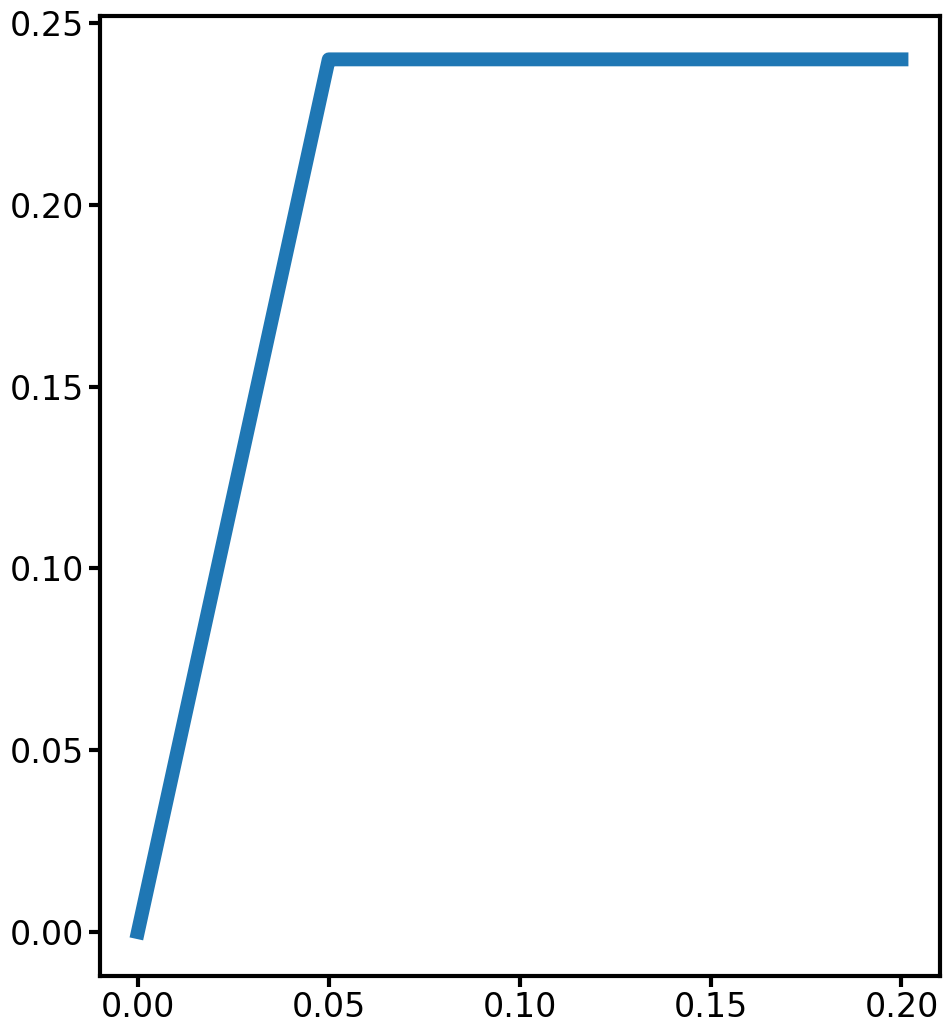

In [19]:
plt.plot(strain,target_Force)

In [29]:
# def makeloss(model):
#     def loss(vs):
#         results=model(vs,key)
#         force=results[0]
#         mean2=jnp.mean(force)**2
#         var=jnp.mean(force**2)
#         return jnp.mean(results[1])/deps/0.01#+(var/mean2-1)
#     return loss

# optimizer=LBFGS(makeloss(model),tol=1e-14,maxiter=20)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)
# def opt_loop(params):
#     params,_=optimizer.run(params)
#     return params
# jopt_loop=jax.jit(opt_loop)

def makeloss(model):
    def loss(vs):
        results=model(vs,key)
        force=jnp.sum(results[1],1)
        return jnp.sum((force-target_Force)**2)#jnp.std(force)-jnp.mean(force)#jnp.mean(results[1])/deps/0.01#+(var/mean2-1)
    return loss


In [34]:
force=jnp.sum(result[1],1)

In [35]:
jnp.sum((force-target_Force)**2)

Array(0.77971096, dtype=float64)

In [10]:
jnp.mean(result[1],1).shape

(101,)

In [8]:
myloss=jax.jit(makeloss(model))
mylossgrad=jax.jit(jax.grad(myloss))

indexmap1=jax.vmap(lambda x,y: x[y[0],y[1]],(None,0))
indexmap=jax.vmap(indexmap1,(None,1),1) # Uses indexes from y, and elements from x, to create array.
def edgeLength(vs):
    mvs=vs[:-4]
    rvs=jnp.tile(mvs,P) #repeat P times
    vsx=rvs.at[0::2].get()
    vsy=rvs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)
    rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
    edges=indexmap(rAvecs,edgeIds).T
    return -((edges[0][0]-edges[0][1])**2+(edges[1][0]-edges[1][1])**2) +0.05 #NLOPT needs negative constraints
edgeLengthJit=jax.jit(edgeLength)
edgeLengthgrad=jax.jit(jax.jacobian(edgeLengthJit))

def angleVecs(v,u): #written by chatgpt, rewrite when you can. returns angle between (-pi/2 , pi*3/2)
            return (jnp.arctan2(u[1], u[0]) - jnp.arctan2(v[1], v[0]) + jnp.pi/2) % (2*jnp.pi) - jnp.pi/2
angleMap=jax.vmap( lambda d,avec,u: angleVecs(u-avec,d-avec))
def angleLength(vs):
    mvs=vs[:-4]
    rvs=jnp.tile(mvs,P) #repeat P times
    vsx=rvs.at[0::2].get()
    vsy=rvs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)
    rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
    cornerVecs=indexmap(rAvecs,angleIds)
    return -angleMap(cornerVecs[:,0],cornerVecs[:,1],cornerVecs[:,2])+1.57/2.0#+0.1745*2
angleLengthJit=jax.jit(angleLength)
angleLengthgrad=jax.jit(jax.jacobian(angleLengthJit))


Array(0.66267038, dtype=float64)

In [29]:
angleMap=jax.vmap( lambda d,avec,u: angleVecs(u-avec,d-avec))

In [20]:
opt.get_errmsg()

In [9]:
def myfunc(x, grad):
    if grad.size > 0:
        grad[:]=mylossgrad(x)
    return float(myloss(x))

def edgeConstraint(result,x,grad):
    if grad.size > 0:
        grad[:]=edgeLengthgrad(x)
    result[:]=edgeLengthJit(x)

def angleConstraint(result,x,grad):
    if grad.size > 0:
        grad[:]=angleLengthgrad(x)
    result[:]=angleLengthJit(x)

feature_size=len(vs)
lower_bound=np.array(feature_size*[-10.0])
lower_bound[-4:-1]=1e-10 #set K bound
opt = nlopt.opt(nlopt.LD_MMA , feature_size) #NLOPT_LD_MMA #GD_STOGO

In [36]:


def myfunc(x, grad):
    if grad.size > 0:
        grad[:]=mylossgrad(x)
    return float(myloss(x))

def edgeConstraint(result,x,grad):
    if grad.size > 0:
        grad[:]=edgeLengthgrad(x)
    result[:]=edgeLengthJit(x)

def angleConstraint(result,x,grad):
    if grad.size > 0:
        grad[:]=angleLengthgrad(x)
    result[:]=angleLengthJit(x)

feature_size=len(vs)
lower_bound=np.array(feature_size*[-10.0])
lower_bound[-4:-1]=1e-10 #set K bound 
opt = nlopt.opt(nlopt.LD_MMA , feature_size) #NLOPT_LD_MMA #GD_STOGO LD_CCSAQ LD_SLSQP LD_LBFGS LD_TNEWTON_PRECOND_RESTART LD_TNEWTON_PRECOND LD_TNEWTON_RESTART LD_TNEWTON LD_VAR2 LD_VAR1
opt.set_param('verbosity',1.0) 
opt.set_param('inner_maxeval',10) 
opt.set_lower_bounds(lower_bound)
opt.set_min_objective(myfunc)
constraint_tolerance=0.02
#opt.add_inequality_mconstraint(edgeConstraint, 96*[constraint_tolerance])
#opt.add_inequality_mconstraint(angleConstraint, 96*[constraint_tolerance])

opt.set_xtol_rel(1e-7)
opt.set_maxtime(60*5)
x = opt.optimize(vs)
print(opt.last_optimize_result(),opt.last_optimum_value())
#minf = opt.last_optimum_value()
#print("optimum at ", x[0], x[1])
#print("minimum value = ", minf)
#print("result code = ", opt.last_optimize_result())

MMA dual converged in 2 iterations to g=-5.22035:
6 0.7797109626732017


In [26]:
result1=model(vs,key)
result2=model(x,key)
#result3=model(x2,key)

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

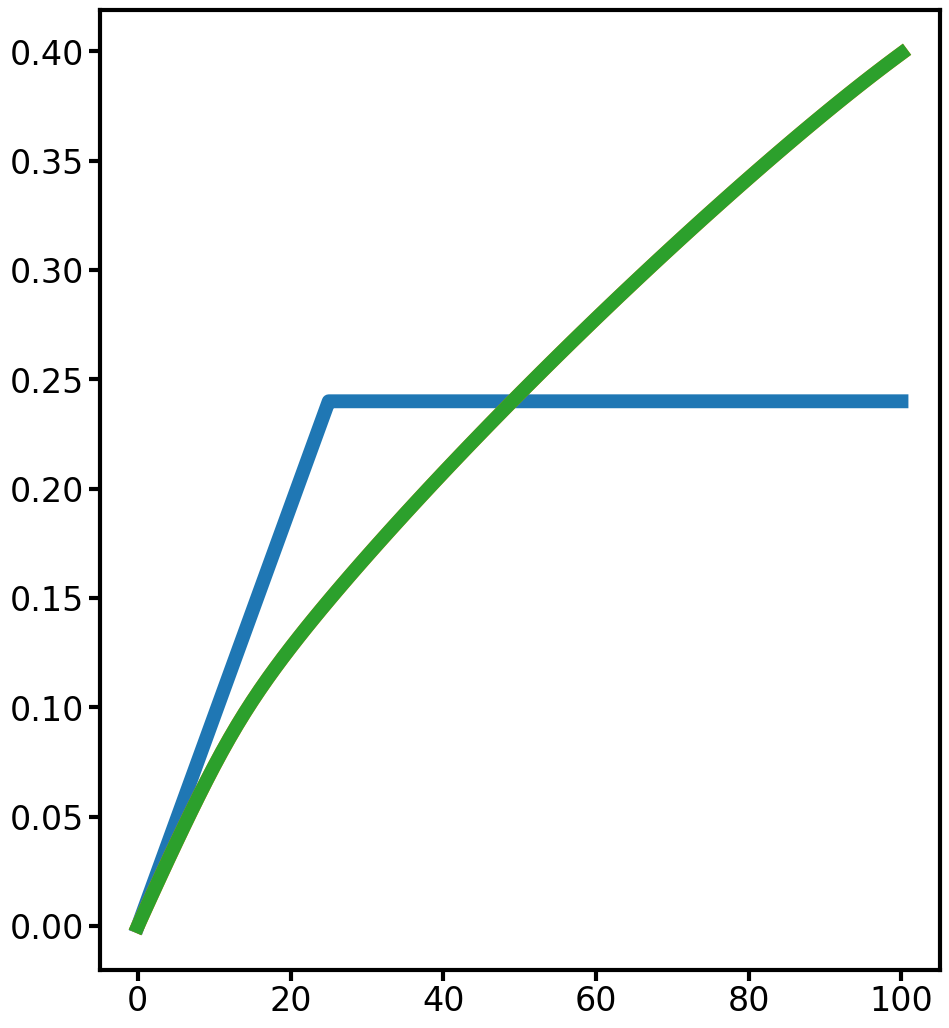

In [27]:
plt.plot(target_Force)
plt.plot(jnp.sum(result1[1],1),'-')
plt.plot(jnp.sum(result2[1],1),'-')
#plt.plot(jnp.mean(result3[1],1),'-')

In [15]:
print(opt.last_optimize_result(),opt.last_optimum_value())

6 0.44862735856454367


In [22]:
myloss(vs)

Array(0.4467241, dtype=float64)

In [28]:
x-vs

Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float64)

In [34]:
mylossgrad(x2)

Array([ 4.21041446e-02, -4.08307622e-02,  2.85911292e-03, -3.18386148e-02,
        1.02704979e-02,  1.57601250e-03,  3.83077947e-03, -1.23748681e-02,
        3.22290737e-02, -9.59452619e-02,  4.16588380e-02,  2.83953446e-02,
        3.58112951e-02,  7.07550301e-02, -1.11913223e-01,  5.06458574e-02,
       -3.28150768e-04, -4.41863918e-02, -2.00398526e-02, -2.26066900e-04,
       -6.26779169e-02,  1.19070092e-01, -1.70011061e-03,  3.97960477e-03,
       -1.30319151e-02,  6.50307426e-02, -1.07153056e-01,  4.11259000e-02,
        4.32307698e-02, -4.76099169e-02,  1.11870730e-01, -1.23208001e-02,
       -8.66752018e-03,  5.23664916e-02, -4.64406572e-02,  2.76827516e-02,
       -1.79337090e-02, -1.08592515e-01,  5.72755492e-02,  4.66747458e-02,
       -2.39712918e-02, -1.18186007e-01,  4.26093587e-02, -1.34733758e-03,
       -3.72972140e-02,  8.10954566e-02, -2.05195943e-02,  1.69178749e-02,
       -2.14077768e-02, -1.60250661e-01,  9.81638418e-02,  1.80404872e-02,
        2.03541981e-02,  

In [40]:
myloss(vs)

Array(1.55970745, dtype=float64)

In [30]:
myloss(x)

Array(1.79017675, dtype=float64)

In [30]:
myloss(x2)

Array(1.95628703, dtype=float64)

In [32]:
myloss(x3)

Array(1.95628703, dtype=float64)

In [14]:
result=model(x,key)

In [ ]:
fig=plt.figure(1,figsize=(7,5))
ax=fig.add_axes(axshape)
spread=[]
stiffness=[]
for i,res in enumerate(results[:]):
    force=res[0]
    mean2=jnp.mean(force)**2
    var=jnp.mean(force**2)
    spread.append(var/mean2-1)
    stiffness.append(jnp.mean(res[1])/deps/0.01)
plt.plot(np.arange(0,len(spread))*20,spread,'o')
plt.plot(np.arange(0,len(stiffness))*20,stiffness,'o')
plt.xlabel("Iteration")
plt.ylabel(r"$<F^2>/<F>^2-1$")

array([ 0,  5, 10, 15, 20, 25])

Text(0, 0.5, 'Force')

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

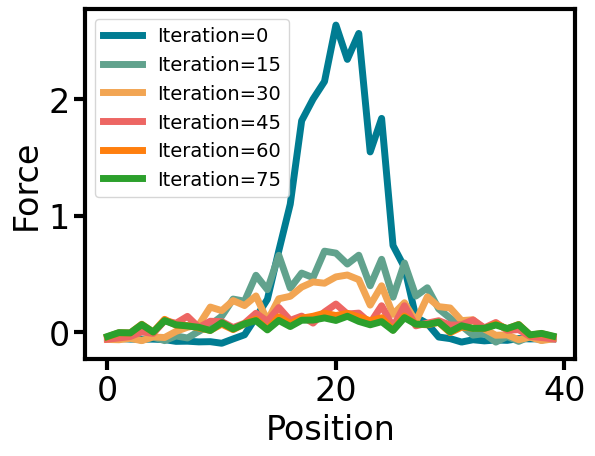

In [77]:
fig=plt.figure(1,figsize=(7,5))
ax=fig.add_axes(axshape)
colors = ['#007c92', '#61a28d', '#f2a553', '#ed6663','C01','C02']
plt.rcParams.update({'font.size': 14})
lw=5
for i,res in enumerate(results[::3]):
    plt.plot(res[0],label='Iteration='+str(15*i),color=colors[i],lw=lw)
plt.legend()
plt.xlabel('Position')
plt.ylabel('Force')
#plt.savefig('indentationTest4.svg')

Text(0, 0.5, 'Force')

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

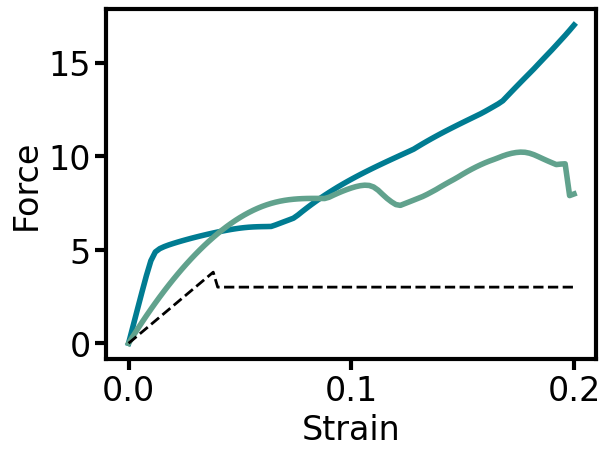

In [9]:
# plt.plot(target)
# plt.plot(result[0])
# plt.plot(result2[0])
# plt.plot(result3[0])
# plt.plot(result4[0])
# plt.plot(result5[0])

#plt.plot(result[0][0])

fig=plt.figure(1,figsize=(7,5))
ax=fig.add_axes(axshape)
colors = ['#007c92', '#61a28d', '#f2a553', '#ed6663']
lw=4
lw2=2
#strain=np.linspace(0,tot_strain,strain_steps)

plt.plot(strain,result[0],label='Iteration=0',color=colors[0],lw=lw)
#plt.plot(strain,result2[0],label='Optimized')
plt.plot(strain,result2[0],label='Iteration=20',color=colors[1],lw=lw)
#plt.plot(strain,result4[0],label='OptimizedV3')
#plt.plot(strain,result4[0],label='Iteration=40',color=colors[2],lw=lw)
#plt.plot(strain,result6[0],label='OptimizedV5')
#plt.plot(strain,result6[0],label='Iteration=60',color=colors[3],lw=lw)
#plt.plot(strain,result7[0],label='Iteration=80',color=colors[0],lw=lw)
#plt.plot(strain,result8[0],label='OptimizedV7')

plt.plot(strain,target,'--',label='Target',color='black',lw=lw2)


plt.xlabel('Strain')
plt.ylabel('Force')
#plt.legend()
#ax.legend(fontsize=18)

Text(0, 0.5, 'Force')

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.


findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

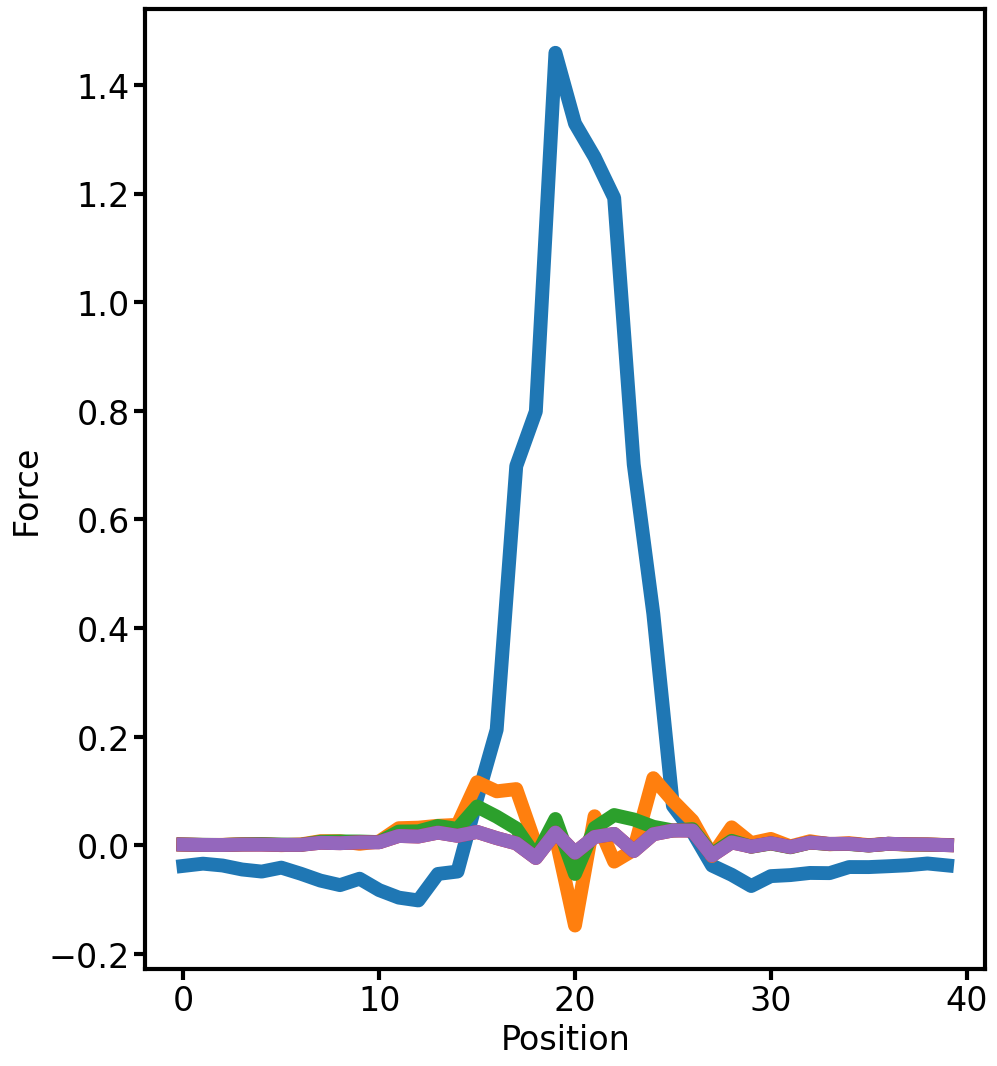

In [46]:
plt.plot(result[0][100])
plt.plot(result2[0][100])
plt.plot(result3[0][100])
plt.plot(result6[0][100])
plt.plot(result7[0][100])

plt.xlabel('Position')
plt.ylabel('Force')

In [35]:
len(results)

6

In [52]:
jnp.save('StressMatch1.npy',newvs5)

In [ ]:
vs=newvs[9]
result=results[9]
nvs=vs.at[:-4].get()
setvs=jnp.tile(nvs,P)
q=result[1][100]

self=Ar

vsx=setvs.at[0::2].get()
vsy=setvs.at[1::2].get()
nvs=jnp.stack((vsx,vsy),axis=1)
rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
for k,ij in enumerate(C[:Nb]):
    i,j=ij
    poli1=Ar[i]
    poli2=Ar[j]
    for pata in poli1.patas:
        if pata.myVecino==poli2:
            pata1=pata
            break
    pata2=pata1.pataVecina
    pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
    pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

self.setVar(q)
plt.figure()

for poli in self:
    
    avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
    color='C0'
    if poli.id in boundary:
        color='C3'
    if len(avecs)<3:
        avecs.append([poli.x,poli.y])
    avecs=np.array(avecs)
    plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
    #plt.text(poli.x,poli.y,str(poli.id),size=10)
plt.axis('scaled')
#plt.xlim(0,Ar.Lx)
#plt.axis('off')

IndexError: Too many indices: 0-dimensional array indexed with 1 regular index.

In [18]:
#Video
import os
qs=result[2]
folder='Kopt6/'
os.makedirs(folder)

for j,q in enumerate(qs):
    Ar.setVar(q)
    self=Ar
    plt.figure()
    for poli in self:
        avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
        color='C0'
        if poli.id in boundary:
            color='C3'
        if len(avecs)<3:
            avecs.append([poli.x,poli.y])
        avecs=np.array(avecs)
        plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
    plt.axis('scaled')
    plt.xlim(-Lx*0.05,Lx*(1.05))
    plt.ylim(-Ly*0.1,Ly*(1.05))
    plt.axis('off')
    plt.savefig(folder+str(j)+'.png')
    plt.close()

In [82]:
result[2].shape

(101, 720)

(np.float64(-2.5092477684092267),
 np.float64(41.69420313659376),
 np.float64(-0.8),
 np.float64(5.8))

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

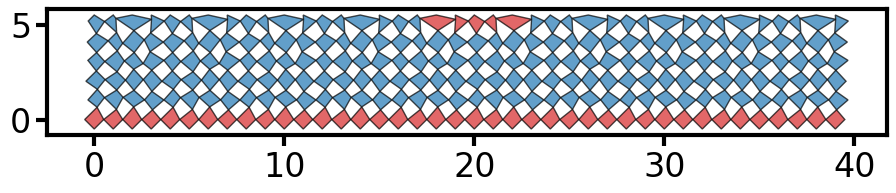

In [15]:
#vs=jnp.array(newvs)
#result=results[9]

nvs=jnp.array(x).at[:-4].get()
setvs=jnp.tile(nvs,P)
q=result[2][0]#result[1][100]

self=Ar

vsx=setvs.at[0::2].get()
vsy=setvs.at[1::2].get()
nvs=jnp.stack((vsx,vsy),axis=1)
rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
for k,ij in enumerate(C[:Nb]):
    i,j=ij
    poli1=Ar[i]
    poli2=Ar[j]
    for pata in poli1.patas:
        if pata.myVecino==poli2:
            pata1=pata
            break
    pata2=pata1.pataVecina
    pata1.avec0=rAvecs[k][0]#pata1.avec0+=nvs[k]
    pata2.avec0=rAvecs[k][1]#pata2.avec0+=nvs[k]

self.setVar(q)
plt.figure()

for poli in self:
    
    avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
    color='C0'
    if poli.id in boundary:
        color='C3'
    if len(avecs)<3:
        avecs.append([poli.x,poli.y])
    avecs=np.array(avecs)
    plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color,alpha=0.7))
    #plt.text(poli.x,poli.y,str(poli.id),size=10)
plt.axis('scaled')
#plt.xlim(0,Ar.Lx)
#plt.axis('off')

In [43]:
def makeloss(model):
    def loss(vs):
        return sum((model(vs,key)[0]-target)**2)
    return loss

optimizer=BFGS(makeloss(model),tol=1e-10,maxiter=2)#,min_stepsize=1e-14,maxls=50)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)
def opt_loop(params):
    params,_=optimizer.run(params)
    return params

newvs=jax.jit(opt_loop)(vs)


INFO: jaxopt.ZoomLineSearch: Iter: 1 Minimum Decrease & Curvature Errors (stop. crit.): 8.657575827416434e+21 Stepsize:1.0  Decrease Error:8.657575827416434e+21  Curvature Error:6570600504234756.0 
INFO: jaxopt.ZoomLineSearch: Iter: 2 Minimum Decrease & Curvature Errors (stop. crit.): inf Stepsize:0.5  Decrease Error:inf  Curvature Error:inf 
INFO: jaxopt.ZoomLineSearch: Iter: 3 Minimum Decrease & Curvature Errors (stop. crit.): inf Stepsize:0.25  Decrease Error:inf  Curvature Error:inf 
INFO: jaxopt.ZoomLineSearch: Iter: 4 Minimum Decrease & Curvature Errors (stop. crit.): inf Stepsize:0.125  Decrease Error:inf  Curvature Error:inf 
INFO: jaxopt.ZoomLineSearch: Iter: 5 Minimum Decrease & Curvature Errors (stop. crit.): inf Stepsize:0.0625  Decrease Error:inf  Curvature Error:inf 
INFO: jaxopt.ZoomLineSearch: Iter: 6 Minimum Decrease & Curvature Errors (stop. crit.): 0.0 Stepsize:0.03125  Decrease Error:0.0  Curvature Error:0.0 
INFO: jaxopt.ZoomLineSearch: Iter: 1 Minimum Decrease & C

In [44]:
result2=model(newvs,key)

In [50]:
jnp.sort(jnp.abs(newvs))

Array([6.88085964e-08, 3.15647755e-05, 2.28176648e-04, 1.38556520e-03,
       3.36340018e-03, 1.21521291e-02, 1.56304153e-02, 1.92924516e-02,
       2.25608830e-02, 3.81464118e-02, 7.44921815e-02, 7.93854881e-02,
       8.68643253e-02, 9.63624663e-02, 1.02497362e-01, 1.08369623e-01,
       1.26106852e-01, 1.43591326e-01, 1.73759941e-01, 2.05576704e-01,
       2.07868509e-01, 2.14798156e-01, 2.15386238e-01, 2.17091710e-01,
       2.49975353e-01, 2.72880388e-01, 2.74753089e-01, 2.86220027e-01,
       2.89984379e-01, 2.93467023e-01, 3.01388355e-01, 3.06641391e-01,
       3.11937323e-01, 3.35624982e-01, 3.46390890e-01, 3.53463071e-01,
       3.68433059e-01, 3.69522324e-01, 3.95124251e-01, 4.11923949e-01,
       4.86736334e-01, 4.98130736e-01, 5.00173982e-01, 5.01907987e-01,
       5.09060742e-01, 5.21423609e-01, 5.29903565e-01, 5.59965573e-01,
       5.62287887e-01, 5.75142251e-01, 5.83363716e-01, 5.91319228e-01,
       5.99859150e-01, 6.07572854e-01, 6.19732296e-01, 6.25277163e-01,
      

(-0.04046946500874021,
 1.0473006089953318,
 -0.04628095110217556,
 1.0128853503637572)

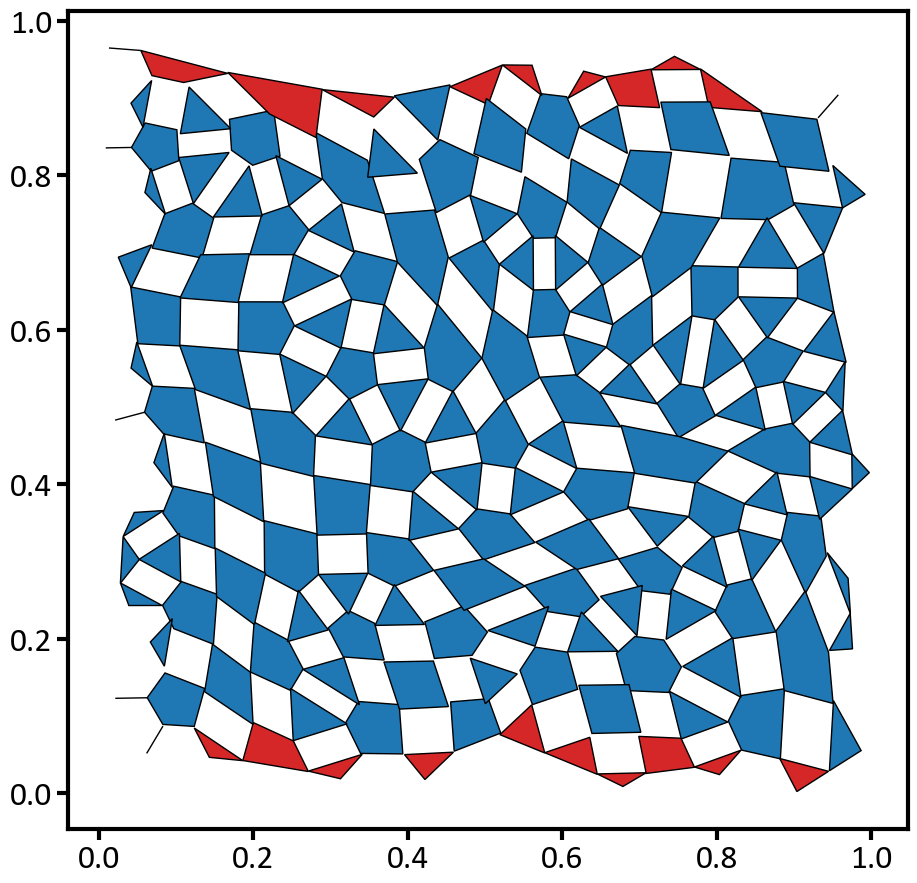

In [47]:
Ar.setVar(result2[1][10])
plt.figure()
for i,poli in enumerate(Ar):
    vecs=list(poli.avec+[poli.x,poli.y])
    if len(poli.avec)<3:
        vecs.append([poli.x,poli.y])
    color='C0'
    if poli.id in boundary:
        color='C3'
    plt.gca().add_patch(matplotlib.patches.Polygon(vecs,edgecolor='black',facecolor=color))
plt.axis('scaled')

In [27]:
result=model(newvs,key)

In [12]:

def sort_vertices(vertices):
    # Calculate centroid
    centroid = np.mean(vertices, axis=0)
    # Sort vertices based on angle from centroid
    vertices_sorted = sorted(vertices, key=lambda v: np.arctan2(v[1]-centroid[1], v[0]-centroid[0]))
    return vertices_sorted

def draw_polygons(x, y, vectors,savefig):
    fig, ax = plt.subplots()
    polygons = []
    for i in range(len(x)):
        vertices = [(x[i] + vector[0], y[i] + vector[1]) for vector in vectors[i]]
        if len(vertices) == 1:
            # Plotting a point if there's only one vertex
            ax.plot([x[i],vertices[0][0]], [y[i],vertices[0][1]], 'r-')
        else:
            vertices_sorted = sort_vertices(vertices)
            polygons.append(Polygon(vertices_sorted, closed=True))
    
    for polygon in polygons:
        ax.add_patch(polygon)
    
    ax.autoscale()
    ax.set_aspect('equal')
    plt.xlim(-1,Lx+1)
    plt.ylim(-1,Ly+1)
    plt.axis('off')

    if savefig==None:
        plt.show()
    else:
        plt.savefig(savefig)
        plt.close()

def init_polydraw(vs):

    Alphas=jnp.zeros((Nb,2))
    A=jnp.zeros((Nb,2))
    
    x=vs.at[::2].get()
    y=vs.at[1::2].get()
    x=x.repeat(2).reshape(Nb,2)
    y=y.repeat(2).reshape(Nb,2)


    tempx=avecx+x
    tempy=avecy+y
    Alphas=jnp.arctan2(tempy,tempx)
    A=jnp.sqrt(tempx**2+tempy**2)


    Avec=[]
    Alphavec=[]
    for i in range(N):
        tempA=[]
        tempAlpha=[]
        for j,tup in enumerate(C):
            for k, num in enumerate(tup):
                if i==num:
                    tempA.append(A[j][k])
                    tempAlpha.append(Alphas[j][k])
        Avec.append(np.array(tempA))
        Alphavec.append(np.array(tempAlpha))
    return Avec,Alphavec


def polydraw(Avec,Alphavec,q,savefig=None):

    x=q[0::3]
    y=q[1::3]

    vectors=[]
    for i in range(N):
        t=q[i*3+2]
        As=Avec[i]
        alphas=Alphavec[i]
        l1=np.cos(alphas+t)*As
        l2=np.sin(alphas+t)*As
        vectors.append([pair for pair in zip(l1, l2)])

    draw_polygons(x, y, vectors,savefig)


c:\Users\dani3\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\dani3\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: not enough values to unpack (expected 2, got 1)

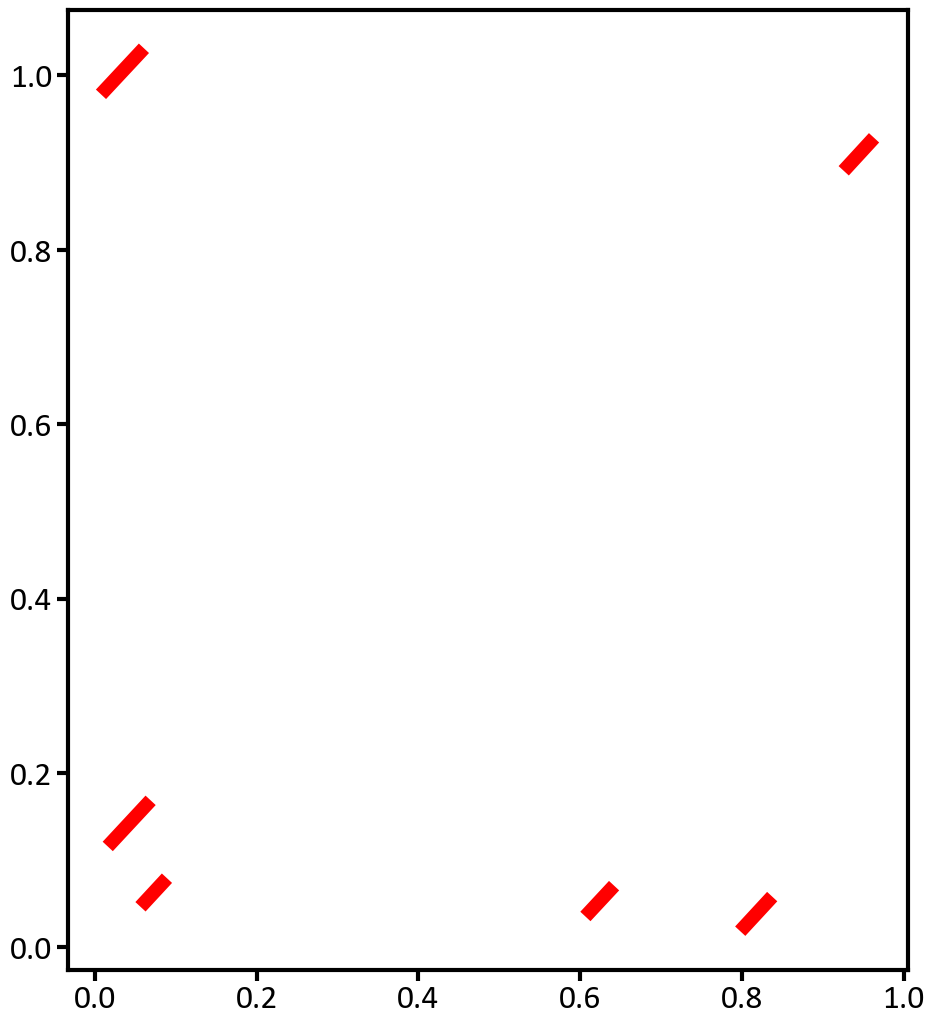

In [13]:
qs=result[1]
Avec,Alphavec=init_polydraw(vs)

q=qs[0]
polydraw(Avec,Alphavec,q)

In [121]:
def makeloss(model):
    def loss(vs):
        #return sum(jnp.max(model(vs,key)[0],axis=1))
        return jnp.std(model(vs,key)[0][-1])
    return loss

optimizer=BFGS(makeloss(model),tol=1e-10,maxiter=2,max_stepsize=0.01)#,min_stepsize=1e-14,maxls=50)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)
def opt_loop(params):
    params,_=optimizer.run(params)
    return params

newvs4=jax.jit(opt_loop)(newvs3)


INFO: jaxopt.ZoomLineSearch: Iter: 1 Minimum Decrease & Curvature Errors (stop. crit.): 1.8474086069259863 Stepsize:0.01  Decrease Error:0.0  Curvature Error:1.8474086069259863 
INFO: jaxopt.ZoomLineSearch: Iter: 1 Minimum Decrease & Curvature Errors (stop. crit.): 0.42887726980521546 Stepsize:0.01  Decrease Error:0.0  Curvature Error:0.42887726980521546 


In [25]:
jnp.std(result[0][-1])

Array(5.03375553, dtype=float64)

TracerIntegerConversionError: The __index__() method was called on traced array with shape int64[].
The error occurred while tracing the function scanned_fun at c:\Users\dani3\anaconda3\Lib\site-packages\jax\_src\lax\control_flow\loops.py:1883 for scan. This concrete value was not available in Python because it depends on the value of the argument loop_carry[0].
See https://jax.readthedocs.io/en/latest/errors.html#jax.errors.TracerIntegerConversionError

In [93]:
result=model(vs,key)

In [122]:
result5=model(newvs4,key)

In [32]:
Foot_shape

Array([], shape=(0,), dtype=float64)

Text(0, 0.5, 'Force')

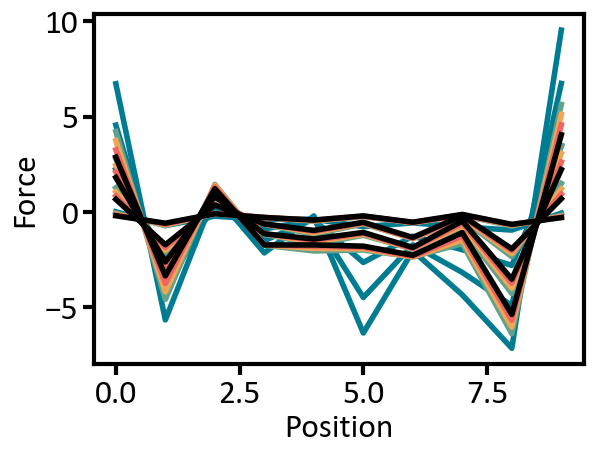

In [123]:

fig=plt.figure(1,figsize=(7,5))
ax=fig.add_axes(axshape)
colors = ['#007c92', '#61a28d', '#f2a553', '#ed6663']
lw=4
lw2=2
#strain=np.linspace(0,tot_strain,strain_steps)

plt.plot(result[0][::25].T,label='Iteration=0',color=colors[0],lw=lw)

plt.plot(result2[0][::25].T,label='Iteration=2',color=colors[1],lw=lw)

plt.plot(result3[0][::25].T,label='Iteration=4',color=colors[2],lw=lw)

plt.plot(result4[0][::25].T,label='Iteration=6',color=colors[3],lw=lw)
plt.plot(result5[0][::25].T,label='Iteration=6',color='black',lw=lw)

#plt.plot(strain,target,'--',label='Target',color='black',lw=lw2)


plt.xlabel('Position')
plt.ylabel('Force')
#plt.legend()
#ax.legend(fontsize=18)

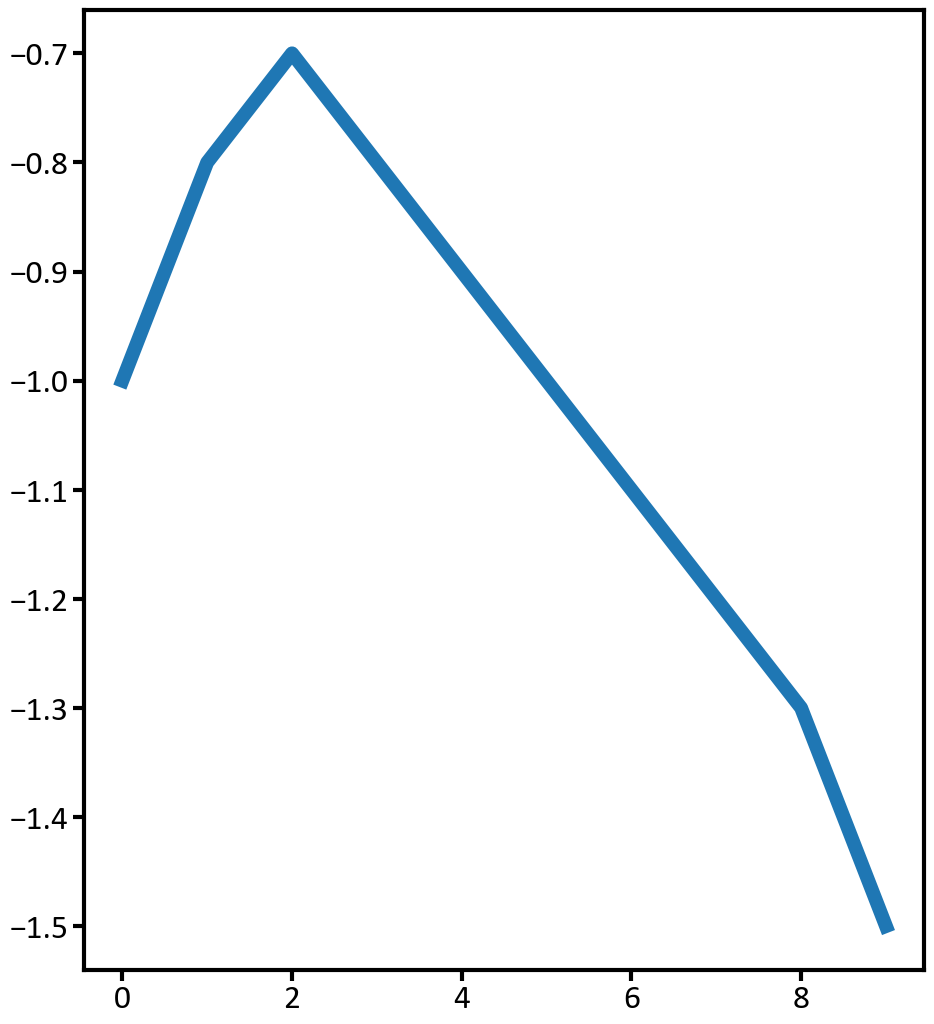

In [6]:
Foot_shape=jnp.array([1.0,0.8,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.5])
plt.plot(-Foot_shape)

In [32]:
asdf=[1,2,3,4,56,7,8,9,0]
asdf[-5+1::3]

[7, 0]

In [16]:
target=np.linspace(0,20,strain_steps)
target[20:]=target[20]
targetBack=np.copy(np.flip(target))
targetBack[:strain_steps-17]=target[17]#np.linspace(,0,strain_steps)
target=np.concatenate([target,targetBack])
strain=np.cumsum(strain_signs*deps)/Ly



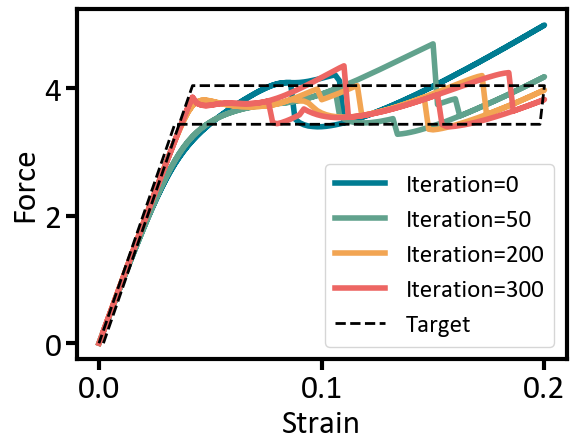

In [130]:
#plt.plot(result[0][0])

fig=plt.figure(1,figsize=(7,5))
ax=fig.add_axes(axshape)
colors = ['#007c92', '#61a28d', '#f2a553', '#ed6663']
lw=4
lw2=2
#strain=np.linspace(0,tot_strain,strain_steps)

plt.plot(strain,result[0],label='Iteration=0',color=colors[0],lw=lw)
#plt.plot(strain,result2[0],label='Optimized')
plt.plot(strain,result2[0],label='Iteration=50',color=colors[1],lw=lw)
#plt.plot(strain,result4[0],label='OptimizedV3')
plt.plot(strain,result7[0],label='Iteration=200',color=colors[2],lw=lw)
#plt.plot(strain,result6[0],label='OptimizedV5')
plt.plot(strain,result9[0],label='Iteration=300',color=colors[3],lw=lw)
#plt.plot(strain,result8[0],label='OptimizedV7')

plt.plot(strain,target,'--',label='Target',color='black',lw=lw2)


plt.xlabel('Strain')
plt.ylabel('Force')
plt.legend()
ax.legend(fontsize=18)

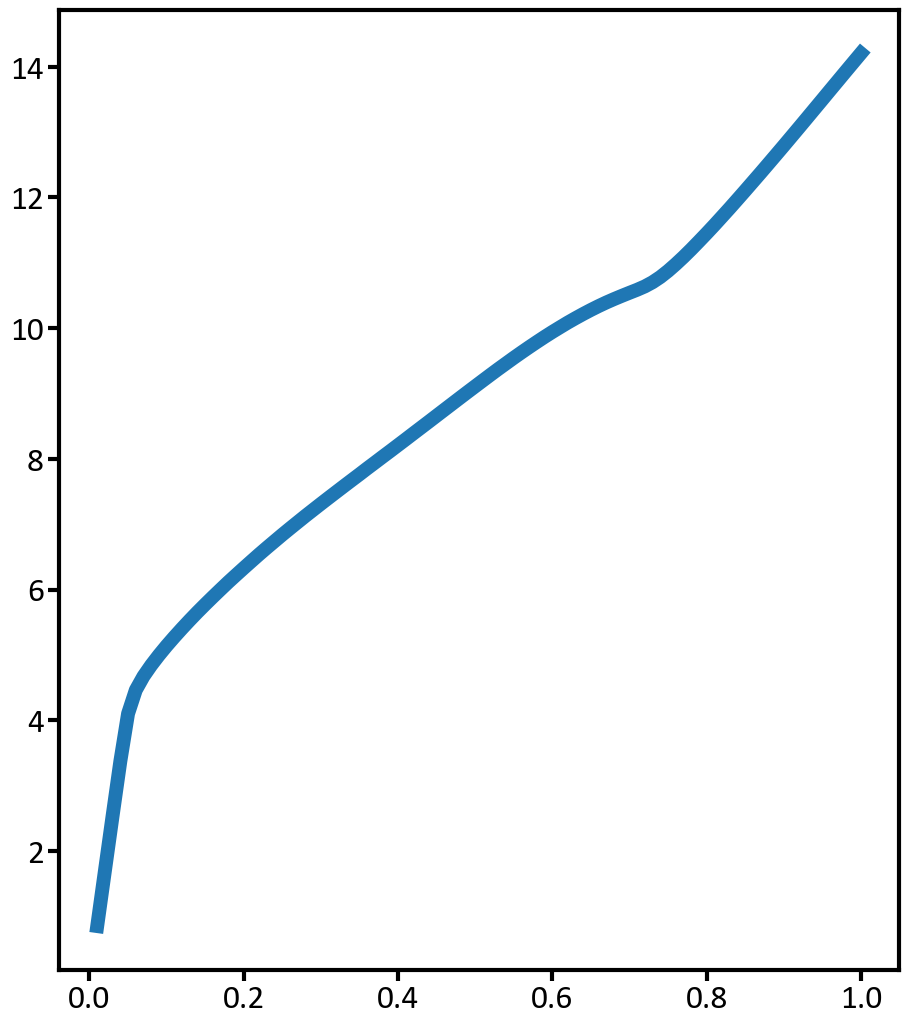

In [24]:
plt.plot(strain,result[0],label='Iteration=0')

In [7]:
result[0]

Array([ 8.93077808e-01,  1.77681612e+00,  2.64805123e+00,  3.49017035e+00,
        4.26410871e+00,  4.87155654e+00,  5.23067040e+00,  5.42555573e+00,
        5.55063552e+00,  5.64502889e+00,  5.72349058e+00,  5.79224145e+00,
        5.86043808e+00,  5.92509739e+00,  5.98862318e+00,  6.04832163e+00,
        6.10763120e+00,  6.16592661e+00,  6.22339813e+00,  6.27952984e+00,
        6.33637554e+00,  6.39192264e+00,  6.44670605e+00,  6.50244178e+00,
        6.55719095e+00,  6.61216608e+00,  6.66649256e+00,  6.72160896e+00,
        6.77657423e+00,  6.83188392e+00,  6.88735391e+00,  6.94404217e+00,
        6.99980793e+00,  7.05581180e+00,  7.11240200e+00,  7.17026918e+00,
        7.22744607e+00,  7.28439187e+00,  7.34335098e+00,  7.40217773e+00,
        7.46189551e+00,  7.52149463e+00,  7.58116299e+00,  7.64372287e+00,
        7.70588431e+00,  7.76791610e+00,  7.83066961e+00,  7.89460006e+00,
        7.95770316e+00,  8.02372195e+00,  8.08889646e+00,  8.15445532e+00,
        8.22249461e+00,  

In [29]:
seed=int(np.random.random()*10000)
key=jax.random.key(seed)

vs=jnp.array(np.random.rand(Nb*2)/10.0)
result=model(vs,key)


In [117]:
def makeloss(model):
    def loss(vs):
        return sum((model(vs)[0]-target)**2)
    return loss

optimizer=BFGS(makeloss(model),tol=1e-10,maxiter=60)#,min_stepsize=1e-14,maxls=50)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)
def opt_loop(params):
    params,_=optimizer.run(params)
    return params

newvs9=jax.jit(opt_loop)(newvs8)

#newvs,_=optimizer.run(vs)


INFO: jaxopt.ZoomLineSearch: Iter: 1 Minimum Decrease & Curvature Errors (stop. crit.): 1214.587536248702 Stepsize:1.0  Decrease Error:1214.587536248702  Curvature Error:0.0 
INFO: jaxopt.ZoomLineSearch: Iter: 2 Minimum Decrease & Curvature Errors (stop. crit.): 449.6332167652463 Stepsize:0.30053630789134833  Decrease Error:449.6332167652463  Curvature Error:0.0 
INFO: jaxopt.ZoomLineSearch: Iter: 3 Minimum Decrease & Curvature Errors (stop. crit.): 212.16413715095018 Stepsize:0.06862421298907115  Decrease Error:212.16413715095018  Curvature Error:0.0 
INFO: jaxopt.ZoomLineSearch: Iter: 4 Minimum Decrease & Curvature Errors (stop. crit.): 14407.952680649272 Stepsize:0.012758271686723516  Decrease Error:456.4890193134662  Curvature Error:14407.952680649272 
INFO: jaxopt.ZoomLineSearch: Iter: 5 Minimum Decrease & Curvature Errors (stop. crit.): 33846.74661763031 Stepsize:0.006379135843361758  Decrease Error:274.29290959912015  Curvature Error:33846.74661763031 
INFO: jaxopt.ZoomLineSearc

In [89]:
result2=model(newvs,key)

In [ ]:
#plt.plot(result[0][0])
strain=np.linspace(0,tot_strain,strain_steps)
plt.plot(strain,result[0],label='Initial Guess')
plt.plot(strain,result2[0],label='Optimized')
plt.plot(strain,target,label='Target')

plt.xlabel('Strain')
plt.ylabel('Force')
plt.legend()

In [67]:
#MAKE VIDEO
import os
folder='FootOpt2/'
os.makedirs(folder)
qs=result5[1]
Avec,Alphavec=init_polydraw(newvs4)
for i,q in enumerate(qs):
    polydraw(Avec,Alphavec,q,savefig=folder+str(i)+'.png')

In [21]:
for i,j in enumerate(range(5,10)):
    print(i,j)

0 5
1 6
2 7
3 8
4 9


In [47]:

qs=result[1]
Avec,Alphavec=init_polydraw(vs)

q=qs[0]
polydraw(Avec,Alphavec,q)


NameError: name 'avecx' is not defined

In [5]:
result[1]

Array([[0.   , 0.   , 0.   , ..., 9.   , 8.982, 0.   ],
       [0.   , 0.   , 0.   , ..., 9.   , 8.964, 0.   ],
       [0.   , 0.   , 0.   , ..., 9.   , 8.946, 0.   ],
       ...,
       [0.   , 0.   , 0.   , ..., 9.   , 7.236, 0.   ],
       [0.   , 0.   , 0.   , ..., 9.   , 7.218, 0.   ],
       [0.   , 0.   , 0.   , ..., 9.   , 7.2  , 0.   ]], dtype=float64)

array([[1, 1],
       [2, 2],
       [3, 3]])

Array(0.89148273, dtype=float64)

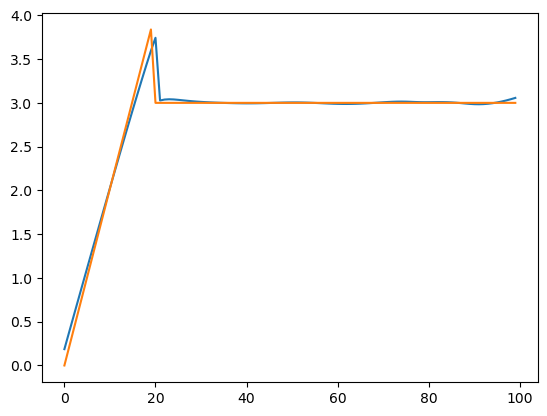

In [16]:
#plt.plot(result[0][0])
plt.plot(result[0])
#plt.plot(result2[0])
#plt.plot(result3[0])
#plt.plot(result4[0])
plt.plot(target)
sum((result[0]-target)**2)

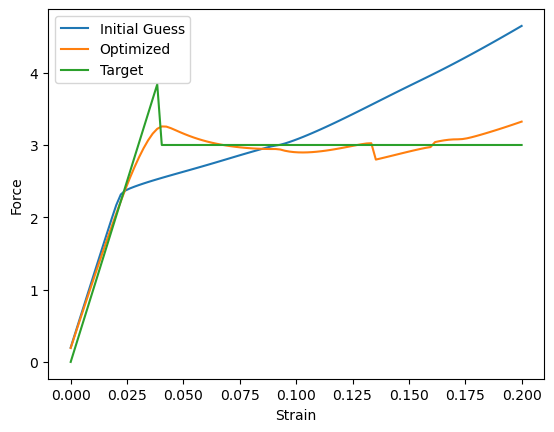

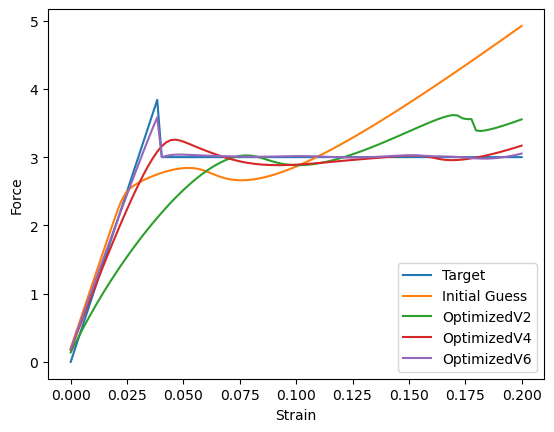

In [39]:
#plt.plot(result[0][0])
strain=np.linspace(0,tot_strain,strain_steps)
plt.plot(strain,target,label='Target')
plt.plot(strain,result[0],label='Initial Guess')
#plt.plot(strain,result2[0],label='Optimized')
plt.plot(strain,result3[0],label='OptimizedV2')
#plt.plot(strain,result4[0],label='OptimizedV3')
plt.plot(strain,result5[0],label='OptimizedV4')
#plt.plot(strain,result6[0],label='OptimizedV5')
plt.plot(strain,result7[0],label='OptimizedV6')
#plt.plot(strain,result8[0],label='OptimizedV7')


plt.xlabel('Strain')
plt.ylabel('Force')
plt.legend()

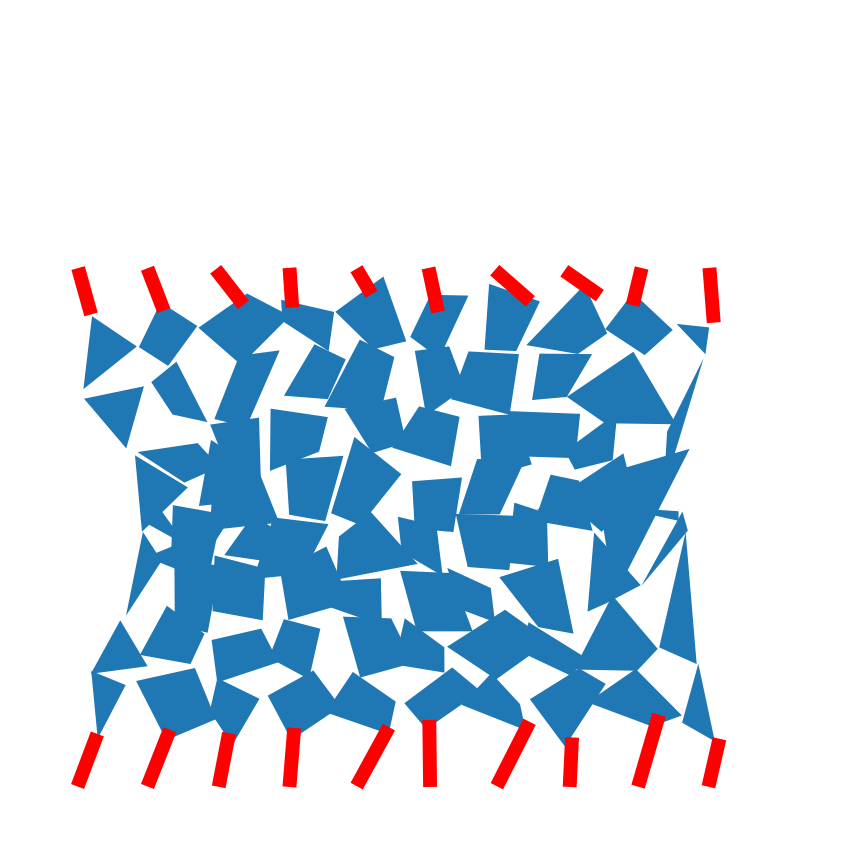

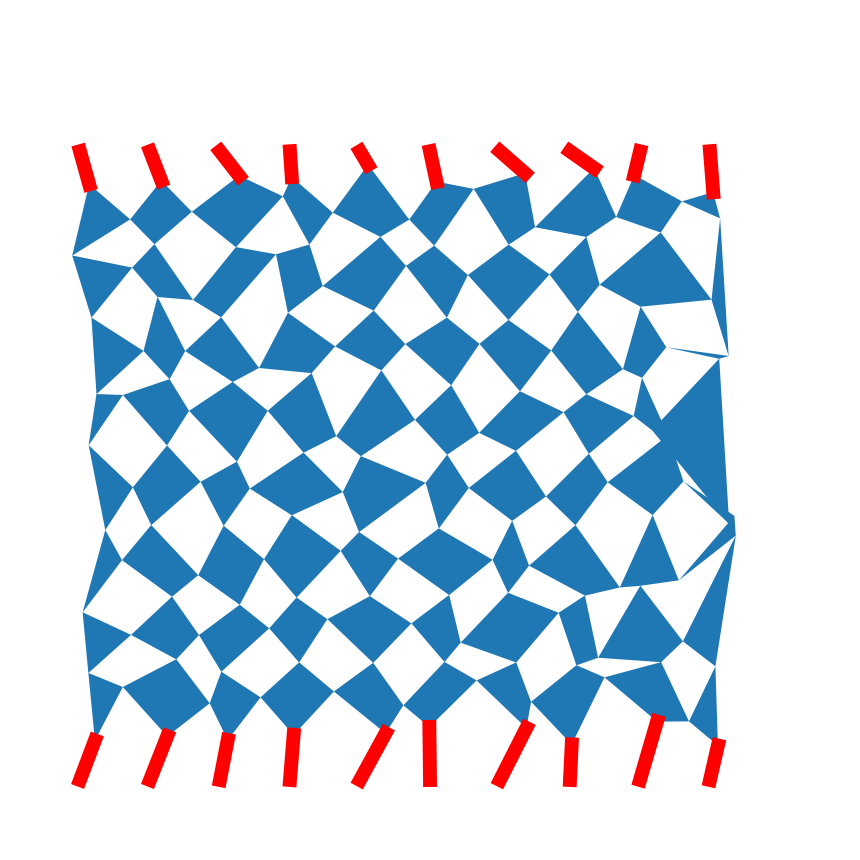

In [120]:
Avec,Alphavec=init_polydraw(newvs9)
polydraw(Avec,Alphavec,result10[1][100])
polydraw(Avec,Alphavec,result10[1][0])

In [14]:
newvs=jnp.array(newvs)

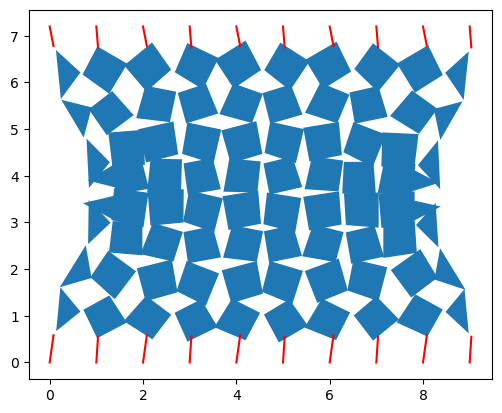

In [21]:
Avec,Alphavec=init_polydraw(vs)
polydraw(Avec,Alphavec,result[1])

In [12]:
newvs=[ 0.01842347,  0.16157559,  0.02265824, -0.021567  ,  0.11280198,
        0.08407426,  0.0722546 , -0.03144905,  0.02824982,  0.14568894,
        0.02442882, -0.05741573,  0.10199251,  0.14623889,  0.0688975 ,
        0.01946217,  0.01545292,  0.0891193 , -0.00186084, -0.03789199,
        0.11149815,  0.13269856,  0.19038077,  0.14314001,  0.12242524,
       -0.17027686,  0.03681287,  0.04877711,  0.07004833,  0.10327358,
        0.08368032,  0.05501053,  0.06982285, -0.01039997,  0.0555692 ,
        0.20769673,  0.10067426,  0.0220655 ,  0.07219141, -0.08254552,
        0.01251526,  0.07868831,  0.0521892 ,  0.13996236,  0.02247029,
       -0.00785143,  0.05302288, -0.09520616,  0.04210427,  0.22224538,
        0.09098331,  0.06577113,  0.06660375,  0.02631211,  0.02876614,
       -0.03752607, -0.00319603, -0.1248494 ,  0.0456157 , -0.14034041,
       -0.07235589,  0.07488916,  0.13088416,  0.21562726,  0.07749551,
        0.00219646, -0.02248985, -0.14459193,  0.05916574,  0.01354151,
        0.03053387,  0.05787228,  0.02072145,  0.08408088,  0.03649217,
        0.09943625,  0.01536688,  0.20609409, -0.02273338,  0.00838295,
        0.09080147,  0.04191435,  0.11666242,  0.18860655,  0.01388052,
        0.09780338, -0.04897658, -0.06432904,  0.07989271, -0.06470053,
       -0.03457672,  0.31772549,  0.03933024,  0.06263973,  0.17527595,
       -0.05132037,  0.10926539,  0.22731334,  0.08627285, -0.15504825,
       -0.07974057, -0.05404096,  0.09551364, -0.10095796,  0.1165117 ,
        0.10464657,  0.03705683,  0.09720823, -0.00445703, -0.08326462,
        0.02395398,  0.05822026,  0.0557745 ,  0.05558255,  0.03921303,
       -0.0122809 ,  0.0915466 ,  0.09952073,  0.06829218,  0.06597543,
        0.06477984, -0.05257057,  0.03664284,  0.07594882,  0.14351348,
        0.24005855,  0.02743481,  0.02749056,  0.02797583, -0.05182076,
        0.00664732, -0.03731396,  0.04272835,  0.17591881,  0.05983208,
        0.44615975,  0.05987891, -0.16954454,  0.03736189,  0.13383554,
        0.08432653, -0.15542022, -0.02145953,  0.05092242,  0.00643843,
       -0.05730001,  0.03624455, -0.03739494,  0.02577897,  0.17436424,
        0.06336461,  0.09074227,  0.02702096,  0.16215437,  0.10046693,
        0.00901049,  0.0177677 ,  0.05143   ,  0.06489609,  0.05230076,
        0.02930836,  0.08390528, -0.03605482, -0.10560908,  0.01009915,
        0.30852128,  0.05519342, -0.38702144,  0.03879689,  0.4615189 ,
        0.01354208,  0.33805217,  0.08808764,  0.46203028,  0.01247826,
       -0.14097978,  0.08860889,  0.12851055,  0.02623531, -0.05881307,
        0.06904073,  0.01734687,  0.06928645,  0.06339738,  0.04003506,
       -0.04174413,  0.09074277,  0.03293461,  0.04990538, -0.01468509,
        0.08231463,  0.03615421,  0.03602716, -0.01862794,  0.07706111,
        0.14506197,  0.13055646, -0.00548035,  0.07010142,  0.11439601,
       -0.00476289, -0.11146359,  0.06110733, -0.04731712,  0.10538387,
       -0.4044409 ,  0.0546288 ,  0.11595174,  0.02069674,  0.254712  ,
        0.07154321,  0.2865451 , -0.07238123,  0.04324884, -0.09286445,
       -0.0735037 ,  0.06163788,  0.03168026,  0.10097725,  0.18007008,
       -0.00212283,  0.06191618, -0.01318622, -0.07730822,  0.06748435,
        0.0993078 ,  0.00526654,  0.02656697,  0.09272828,  0.21134714,
        0.0745874 ,  0.07152161,  0.09802578, -0.09027976,  0.02425881,
       -0.08360454, -0.00463781,  0.03703666,  0.10721609,  0.24615429,
        0.05422107,  0.02899636,  0.03697962, -0.16597696, -0.00209004,
        0.04657338,  0.19498858,  0.06985718,  0.08359296, -0.10792575,
        0.21347109,  0.13091288,  0.0958549 ,  0.17420304,  0.03788747,
        0.07495061,  0.03881964, -0.11061656,  0.0107098 ,  0.04938873,
        0.08226001,  0.0300391 ,  0.10069039,  0.14121665,  0.00581089,
        0.0458068 ,  0.06592865, -0.04691393,  0.01514672,  0.07306615,
        0.06731279,  0.22492993,  0.08053831,  0.18632797,  0.03573235,
       -0.06847593,  0.03331356, -0.06766506,  0.06775326,  0.05960856,
        0.07563747,  0.11885418,  0.06233432,  0.0233432 , -0.16398686,
        0.01857129,  0.03397536,  0.13455791,  0.09834463,  0.185999  ,
        0.07099961, -0.14900897,  0.02749345, -0.01178681,  0.02187575,
        0.08626774,  0.02060636,  0.07412399,  0.03128364, -0.00665609,
        0.04525141, -0.0704091 ,  0.0589971 ,  0.03742582,  0.05046063,
        0.14925406,  0.01403684,  0.09184113,  0.01388723,  0.00356234,
        0.07840477, -0.02502683,  0.04319263,  0.09983915,  0.03548502,
        0.22094059,  0.06214067,  0.03777606,  0.03147536,  0.03649524,
        0.05396249,  0.0992059 ,  0.00539308, -0.07184026]

In [7]:
newvs,loss,grads=optModel(vs)

ValueError: too many values to unpack (expected 3)

In [ ]:
result2=model(newvs)

In [11]:
newvs2,loss2,grads2=optModel(newvs)
result3=model(newvs2)

In [13]:
newvs3,loss2,grads2=optModel(newvs2)
result4=model(newvs3)

In [15]:
newvs4,loss2,grads2=optModel(newvs3)
result5=model(newvs4)

In [125]:
res=model(0.1)

In [6]:
num_opt_steps=100

learning_rate = 1e-3
optimizer = optax.adam(learning_rate)

def makeloss(model):
    def loss(vs):
        return sum((model(vs)[0]-target)**2)
    return loss
#dV=jax.jacfwd(makeloss(model,target))
dV=jax.jit(jax.grad(makeloss(model)))
#loss=makeloss(model)

In [52]:
vs=jnp.array(np.random.rand(Nb*2)/10.0)
dV(vs)

Array([-2.73098622e-01, -8.76347664e+00,  1.43244671e-01,  5.60277023e+00,
       -8.53188439e-01, -5.83189848e+00,  3.66273497e+00,  2.49701660e+01,
       -4.02074444e+00, -1.98746140e+01,  3.32340590e+00,  1.87944370e+01,
       -2.84701018e+00, -2.13073644e+01,  1.13092887e+00,  7.19520562e+00,
       -2.80178586e-01, -6.45979945e+00,  3.04947394e-01,  8.90475224e+00,
       -1.86948213e+00, -6.39571458e+00, -1.77680637e+00, -6.43222306e+00,
       -1.74238718e+00,  1.84905577e+01,  3.47379567e+00, -1.06977451e+01,
       -3.51851227e+00, -1.83523228e+01, -7.17590988e-01,  2.89298642e+01,
       -1.15724330e+00,  8.12453303e+00, -1.37016914e+00, -3.23576555e+01,
        4.51525060e-01, -4.46410448e-01,  2.00551377e+00,  4.39888065e+01,
        1.02792081e+00, -7.49802134e+00, -1.57635764e+00, -4.14104445e+01,
        2.93619991e+00,  1.65316913e+01,  2.20657760e+00,  2.98129989e+01,
        1.74384449e+00, -1.71947908e+01,  4.31787364e-01, -3.47648102e+01,
        1.99294693e+00,  

In [98]:
jax.grad(model)(vs)

CustomVJPException: Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how to differentiate the custom_vjp function with respect to explicit input parameters. Try passing the closed-over value into the custom_vjp function as an argument, and adapting the custom_vjp fwd and bwd rules.

In [108]:
init_x=jnp.array([1.0,2.0,3.0])
def implicit_layer(outer_y):
  def closure(x, inner_y):
    loss = jnp.sum(x**2)*sum(inner_y**4*x**2)+jnp.sum(x**2)
    return loss

  lbfgs = LBFGS(closure)
  out, _ = lbfgs.run(init_x, inner_y=outer_y)
  return sum(out)

test=jax.grad(implicit_layer)


In [109]:
test(jnp.array([1.0,2.0,3.0]))

Array([0.0000000e+00, 6.1091906e-10, 9.9497341e-09], dtype=float64)

In [2]:
Avec,Alphavec=init_polydraw(vs)
polydraw(Avec,Alphavec,result[1])

NameError: name 'vs' is not defined

In [30]:
init_x=jnp.array([1.0,2.0,3.0])
def implicit_layer(inner_y):
  def closure(x):
    loss = jnp.sum(x**2)*sum(inner_y**4*x**2)+jnp.sum(x**2)
    return loss

  lbfgs = LBFGS(closure)
  out, _ = lbfgs.run(init_x, inner_y=inner_y)
  return sum(out)

test=jax.grad(implicit_layer)


In [31]:
test(init_x)

TypeError: implicit_layer.<locals>.closure() got an unexpected keyword argument 'inner_y'

In [59]:
import numpy as np
from jax import grad, jit
from jax import lax
from jax import random
import jax
import jax.numpy as jnp
import optax
from jaxopt import LBFGS, BFGS

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "cpu")

#Ar=Auxetic('random64Dual0.dat') 'square10x10.dat'
P=4 #Periodicity

Ars=[]
newdata=[]
for i in range(P):
    Ars.append(Auxetic('random64Dual0.dat'))
sizeAr=len(Ars[0])

for i,Ar in enumerate(Ars):
    x=Ar.getVar() #update positions
    x[0::3]+=Ar.Lx*i
    Ar.setVar(x)
    
    for poli in Ar: #update neighbours
        for pi,pata in enumerate(poli.patas):
            neigh=pata.myVecino
            pataN=pata.pataVecina
            
            if (poli.x-neigh.x)>0.5*Ar.Lx:
                #print(neigh.id,(i+1)%P,pi)
                pata.myVecino=Ars[(i+1)%P][neigh.id]
                id_pataN=neigh.patas.index(pataN)
                pata.pataVecina=Ars[(i+1)%P][neigh.id].patas[id_pataN]
            elif (neigh.x-poli.x)>0.5*Ar.Lx:
                pata.myVecino=Ars[(i-1)%P][neigh.id]
                id_pataN=neigh.patas.index(pataN)
                pata.pataVecina=Ars[(i-1)%P][neigh.id].patas[id_pataN]

    for poli in Ar:#update ids
        poli.id+=sizeAr*i
    newdata.append(Ar.data)
newdata=[item for row in newdata for item in row]
Ar=Ars[0]
Ar.data=newdata #put all into a single array


In [49]:
Ars[1][85].patas

(np.float64(-0.22049806655838392),
 np.float64(4.238279286062825),
 np.float64(-0.08967095127839247),
 np.float64(1.0729896382049364))

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

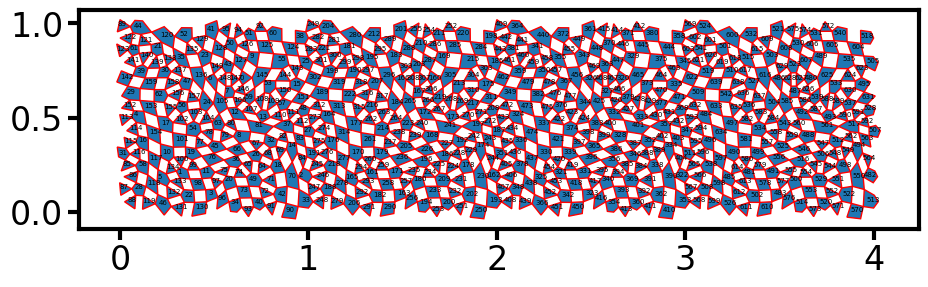

In [60]:
for poli in Ar:
    
    avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
    color='C0'
    avecs=np.array(avecs)
    plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='red',facecolor=color))
    plt.text(poli.x-0.025,poli.y-0.00025,str(poli.id),size=5)
plt.axis('scaled')
#plt.xlim(0,Ar.Lx)

In [65]:
for pata in Ar[305].patas:
    #print(pata.myVecino.id)
    print(pata.pataVecina.myVecino.id)

305
305
305
305
305


In [38]:
for pata in Ar[9].patas:
    print(pata.myVecino.id)

8
99
100
19


In [39]:
for pata in Ar[0].patas:
    print(pata.myVecino.id)

309
90
1
10


In [40]:
for pata in Ar[300].patas:
    print(pata.myVecino.id)

209
390
301
310


Text(0, 0.5, 'Force')

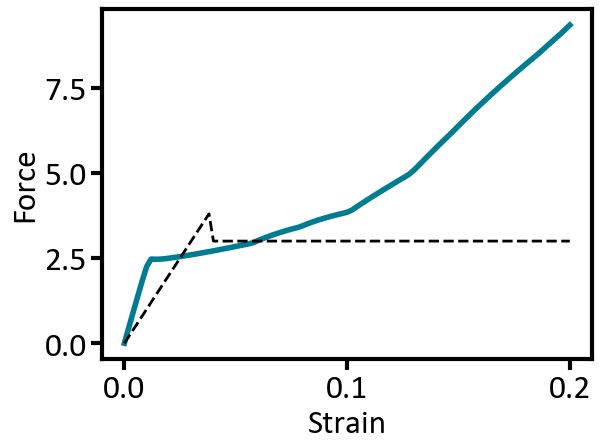

In [12]:
# plt.plot(target)
# plt.plot(result[0])
# plt.plot(result2[0])
# plt.plot(result3[0])
# plt.plot(result4[0])
# plt.plot(result5[0])

#plt.plot(result[0][0])

fig=plt.figure(1,figsize=(7,5))
ax=fig.add_axes(axshape)
colors = ['#007c92', '#61a28d', '#f2a553', '#ed6663']
lw=4
lw2=2
#strain=np.linspace(0,tot_strain,strain_steps)

plt.plot(strain,result[0],label='Iteration=0',color=colors[0],lw=lw)
#plt.plot(strain,result2[0],label='Optimized')


plt.plot(strain,target,'--',label='Target',color='black',lw=lw2)


plt.xlabel('Strain')
plt.ylabel('Force')
#plt.legend()
#ax.legend(fontsize=18)

In [112]:
vectors=[]
for i in range(N):
    t=q[i*3+2]
    As=Avec[i]
    alphas=Alphavec[i]
    l1=np.cos(alphas)*As
    l2=np.sin(alphas)*As
    vectors.append([pair for pair in zip(l1, l2)])

In [113]:
vectors[10]

[(-2.1855694e-08, -0.5), (0.5, 0.0), (-2.1855694e-08, 0.5)]

In [108]:
vectors2[0]

[(1, 1), (2, 0), (1, -1), (-1, -1), (-2, 0), (-1, 1)]

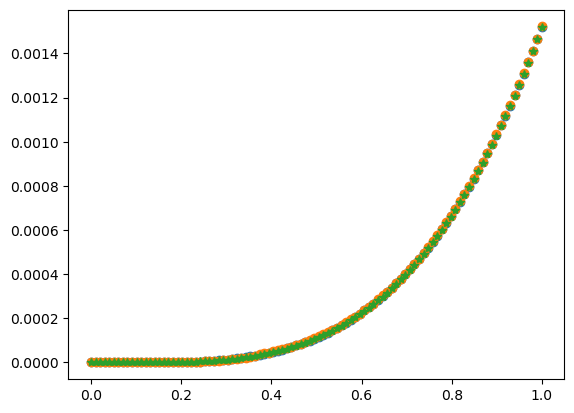

In [11]:

ys=jnp.linspace(0,N+1,N+2)
ls=jnp.array([1.0]*(N-1))
steps=100
learning_rate=1e-3

optimizer = optax.amsgrad(learning_rate)
model=setup(N,steps,ls,ys,while_loop=1,optimizer=optimizer,tol=1e-12)
strain=np.linspace(0,1,steps)

#ks=jnp.array([0.0]*(N+1))#+jnp.array(np.random.rand(N+1)-0.5)*2.0
#ks=jnp.array(np.random.rand(N+1)-0.5)
plt.plot(strain,model(ks),'o',label='random')

optimizer = optax.yogi(0.1)
model=setup(N,steps,ls,ys,while_loop=1,optimizer=optimizer,tol=1e-10)
plt.plot(strain,model(ks),'o',label='random')


learning_rate=0.6 #GD has problems under 0.5 learning-rate
def myGD(grads,params):
    return params-grads*learning_rate
model=setup(N,steps,ls,ys,while_loop=0,optimizer=myGD,tol=1e-10,no_optax=1,steps_per_cond=10000)
plt.plot(strain,model(ks),'*',label='random')


In [12]:
ys=jnp.linspace(0,N+1,N+2)
ls=jnp.array([1.0]*(N-1))
steps=100
learning_rate=1e-3

optimizer = optax.amsgrad(learning_rate)
model=setup(N,steps,ls,ys,while_loop=1,optimizer=optimizer,tol=1e-12)
strain=np.linspace(0,1,steps)

In [3]:
ys=jnp.linspace(0,N+1,N+2)
ls=jnp.array([1.0]*(N-1))
steps=100
learning_rate=1e-3

optimizer = optax.amsgrad(learning_rate)
model=setup(N,steps,ls,ys,while_loop=0,optimizer=optimizer,steps_per_cond=10000)
strain=np.linspace(0,1,steps)

In [6]:
#f=jit(jax.jacfwd(makeloss(model)))
#f=jit(jax.grad(makeloss(model)))

def makeDesignOpt(model,target):

    num_opt_steps=100
    learning_rate = 1e-1
    optimizer = optax.amsgrad(learning_rate)

    def makeloss(model,target):
        def loss(ks):
            return sum((model(ks)-target)**2)
        return loss
    #dV=jax.jacfwd(makeloss(model,target))
    dV=jax.jacrev(makeloss(model,target))

    def opt_step(state):
        params,grads,opt_state=state
        grads = dV(params)
        updates, opt_state = optimizer.update(grads, opt_state,params)
        params=optax.apply_updates(params, updates)
        return params,grads,opt_state

    def opt_loop(params):
        opt_state = optimizer.init(params)
        grads=dV(params)
        state=(params,grads,opt_state)
        params,grads,opt_state=lax.fori_loop(0,num_opt_steps, lambda j,statevar: opt_step(statevar)  ,state)
        return params
    
    return jax.jit(opt_loop)

target=np.linspace(0,0.1,steps)
target[steps//2:]=target[steps//2-1]
#target[10:]=np.linspace(0,0.05,steps)[10:]
target=jnp.array(target)

ksi=jnp.array([0.0]*(N+1))
#ksi=jnp.array([1.0]*(N+1))+jnp.array(np.random.rand(N+1)-0.5)*2.0

ks=makeDesignOpt(model,target)(ksi)


Text(0, 0.5, 'Force')

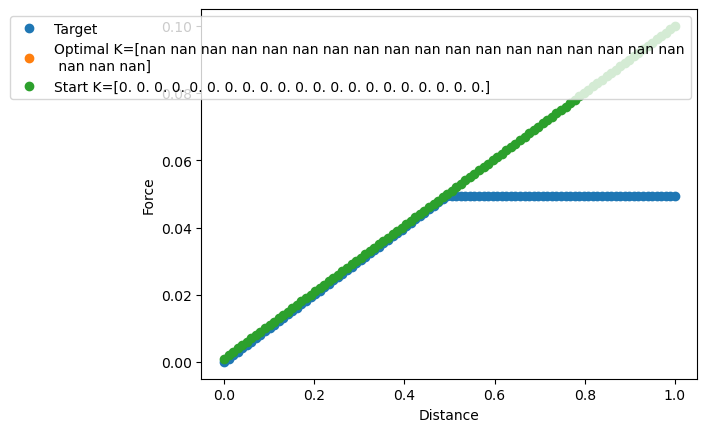

In [7]:
strain=np.linspace(0,1,len(target))
plt.plot(strain,target,'o',label='Target')
plt.plot(strain,model(ks),'o',label='Optimal'+' K='+str(ks))
plt.plot(strain,model(ksi),'o',label='Start'+' K='+str(ksi))
#plt.plot(strain,model(np.random.rand(N+1)*4),'o',label='random')
plt.legend()
plt.xlabel('Distance')
plt.ylabel('Force')

In [7]:
strain=np.linspace(0,1,steps)
plt.plot(strain,model(jnp.array(np.random.rand(N+1))*4),'o',label='random')
plt.legend()
plt.xlabel('Distance')
plt.ylabel('Force')


Array([3.6654775 , 0.0436688 , 3.8030946 , 3.0288334 , 1.7185689 ,
       0.47843727], dtype=float32)

In [34]:
a,b=wtf

In [44]:
def opt_step(state):
    a,b=state
    a+=1
    return a,b

state0=(1,{'hola':5})

asdf=lax.fori_loop(0,10, lambda j,state: opt_step(state)  ,state0)

In [45]:
asdf

(Array(11, dtype=int32, weak_type=True),
 {'hola': Array(5, dtype=int32, weak_type=True)})

In [13]:
optimizer=optax.sgd(1e-1)
opt_state = optimizer.init([0.1,0.2,0.3])

In [15]:
updates, opt_state = optimizer.update([1,2,3], opt_state)

In [16]:
opt_state

(EmptyState(), EmptyState())

In [3]:
def givefun(flag):

    def myfun(x):

        if flag==1:
            def fun(x):
                return x**3
        else:
            def fun(x):
                return x**2
            
        return fun(x)+1
            
        
    return jax.jit(myfun)



In [11]:
fun=jax.grad(givefun(0))

In [12]:
fun(2.0)

Array(4., dtype=float32, weak_type=True)

In [4]:
import jax
import jax.numpy as jnp
asdf=jnp.array([1,2,3,4,5])

In [5]:
jnp.cos(asdf)

Array([ 0.5403023 , -0.41614684, -0.9899925 , -0.6536436 ,  0.2836622 ],      dtype=float32)

In [7]:
Alphas=jnp.zeros((4,2))

In [15]:
import numpy as np
asdf=np.array([1,2,3,4,5,6,7,8,9])

In [13]:
asdf.repeat(5)

array([1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3])

In [21]:
mask=jnp.ones(20)
mask=mask.at[:2*3].set(0.0)
mask=mask.at[-2*3:].set(0.0)

In [25]:
u=[0,1]
v=[-1,0]

angleVecs(u,v)

270.0

In [26]:

asdf1=jnp.array([1,2,3,4,5])
asdf2=jnp.array([1,7,3,4,6])

def fun(carry,x):
    x1,x2=x
    #print(x1,x2)

    return carry,(x1,x2)


res=lax.scan(fun,0.0,(asdf1,asdf2))

In [9]:
import jax.numpy as jnp
vs=jnp.array(np.random.rand(Nb*2)/10000.0)

In [10]:
Avecs=jnp.array(Avecs)

In [19]:
vsx=vs.at[::2].get()
vsy=vs.at[1::2].get()
nvs=np.stack((vsx,vsy),axis=1)


In [22]:
Avecs[0]

Array([[-0.02802295, -0.00035872],
       [ 0.02802295,  0.00035872]], dtype=float32)

In [30]:
nvs[0]*50000

array([1.5328443, 2.24319  ], dtype=float32)

In [41]:
Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])

Array([[[ 1.5048213 ,  2.2428312 ],
        [ 1.5608673 ,  2.2435489 ]],

       [[ 1.9492487 ,  1.8583196 ],
        [ 1.967944  ,  1.9173537 ]],

       [[ 0.5736695 ,  3.7783334 ],
        [ 0.4920259 ,  3.7626326 ]],

       ...,

       [[ 0.04568376,  0.03024854],
        [-0.04568376, -0.03024854]],

       [[-0.0044453 ,  0.04147029],
        [ 0.0044453 , -0.04147029]],

       [[-0.03358202,  0.01696831],
        [ 0.03358202, -0.01696831]]], dtype=float32)

In [43]:
Avecs[1]+nvs[1]*50000

Array([[1.9492487, 1.8583196],
       [1.967944 , 1.9173537]], dtype=float32)

In [38]:
nvs[:,jnp.newaxis,:]

array([[[3.06568872e-05, 4.48638020e-05]],

       [[3.91719259e-05, 3.77567339e-05]],

       [[1.06569541e-05, 7.54096618e-05]],

       [[7.61230185e-05, 1.88956110e-05]],

       [[3.36270678e-05, 2.52174304e-05]],

       [[7.08745138e-05, 2.40839763e-05]],

       [[4.10361099e-05, 4.14367969e-05]],

       [[9.70047113e-05, 5.81421737e-05]],

       [[5.58248903e-05, 8.19249617e-05]],

       [[3.56016358e-07, 8.47865012e-05]],

       [[7.33661873e-05, 5.43979768e-05]],

       [[7.33869965e-05, 8.65575203e-05]],

       [[7.51205662e-05, 4.17974079e-05]],

       [[6.72014285e-05, 1.54312711e-05]],

       [[7.27058505e-05, 5.66116505e-05]],

       [[8.25278257e-05, 9.94028305e-05]],

       [[3.48460017e-05, 1.01915703e-05]],

       [[9.11566822e-05, 4.26976039e-05]],

       [[6.87044812e-05, 4.48591527e-06]],

       [[5.68276482e-06, 8.49429489e-05]],

       [[6.58335775e-05, 3.13139572e-05]],

       [[6.47804482e-05, 7.98503534e-05]],

       [[9.51239999e-05, 6.38899

In [39]:
nvs

array([[3.06568872e-05, 4.48638020e-05],
       [3.91719259e-05, 3.77567339e-05],
       [1.06569541e-05, 7.54096618e-05],
       [7.61230185e-05, 1.88956110e-05],
       [3.36270678e-05, 2.52174304e-05],
       [7.08745138e-05, 2.40839763e-05],
       [4.10361099e-05, 4.14367969e-05],
       [9.70047113e-05, 5.81421737e-05],
       [5.58248903e-05, 8.19249617e-05],
       [3.56016358e-07, 8.47865012e-05],
       [7.33661873e-05, 5.43979768e-05],
       [7.33869965e-05, 8.65575203e-05],
       [7.51205662e-05, 4.17974079e-05],
       [6.72014285e-05, 1.54312711e-05],
       [7.27058505e-05, 5.66116505e-05],
       [8.25278257e-05, 9.94028305e-05],
       [3.48460017e-05, 1.01915703e-05],
       [9.11566822e-05, 4.26976039e-05],
       [6.87044812e-05, 4.48591527e-06],
       [5.68276482e-06, 8.49429489e-05],
       [6.58335775e-05, 3.13139572e-05],
       [6.47804482e-05, 7.98503534e-05],
       [9.51239999e-05, 6.38899146e-05],
       [9.25150307e-05, 2.87275907e-05],
       [6.711460

In [88]:
def Rotation(theta):
    return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
RotationM=jax.vmap(Rotation)

In [94]:
RotationM(q)

Array([[[ 0.87758256, -0.47942554],
        [ 0.47942554,  0.87758256]],

       [[ 0.99500417, -0.09983342],
        [ 0.09983342,  0.99500417]],

       [[ 0.98006658, -0.19866933],
        [ 0.19866933,  0.98006658]],

       [[ 0.95533649, -0.29552021],
        [ 0.29552021,  0.95533649]],

       [[ 0.92106099, -0.38941834],
        [ 0.38941834,  0.92106099]],

       [[ 0.87758256, -0.47942554],
        [ 0.47942554,  0.87758256]],

       [[ 0.82533561, -0.56464247],
        [ 0.56464247,  0.82533561]],

       [[ 0.76484219, -0.64421769],
        [ 0.64421769,  0.76484219]]], dtype=float64)

In [90]:
Rotation(q[0])

Array([[ 0.87758256, -0.47942554],
       [ 0.47942554,  0.87758256]], dtype=float64)

In [87]:
q=jnp.array([0.5,0.1,0.2,0.3,0.4,0.5,0.6,0.7])

In [68]:
Rotation(0.5)

array([[ 0.87758256, -0.47942554],
       [ 0.47942554,  0.87758256]])

In [70]:
Rotation(q).T

array([[[ 0.87758256,  0.47942554],
        [-0.47942554,  0.87758256]],

       [[ 0.99500417,  0.09983342],
        [-0.09983342,  0.99500417]],

       [[ 0.98006658,  0.19866933],
        [-0.19866933,  0.98006658]],

       [[ 0.95533649,  0.29552021],
        [-0.29552021,  0.95533649]],

       [[ 0.92106099,  0.38941834],
        [-0.38941834,  0.92106099]],

       [[ 0.87758256,  0.47942554],
        [-0.47942554,  0.87758256]],

       [[ 0.82533561,  0.56464247],
        [-0.56464247,  0.82533561]],

       [[ 0.76484219,  0.64421769],
        [-0.64421769,  0.76484219]]])

In [17]:
import numpy as np
from jax import grad, jit
from jax import lax
from jax import random
import jax
import jax.numpy as jnp
import optax
from jaxopt import LBFGS, BFGS

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platform_name", "cpu")

#Ar=Auxetic('random64Dual0.dat')
periodicity=4

Ars=[]
newdata=[]
for i in range(4):
    Ars.append(Auxetic('square10x10.dat'))
for i,Ar in enumerate(Ars):
    x=Ar.getVar()
    x[0::3]+=Ar.Lx*i
    Ar.setVar(x)
    newdata.append(Ar.data)
newdata=[item for row in newdata for item in row]
Ar=Ars[0]
Ar.data=newdata

findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: Font family 'Calibri' not found.
findfont: F

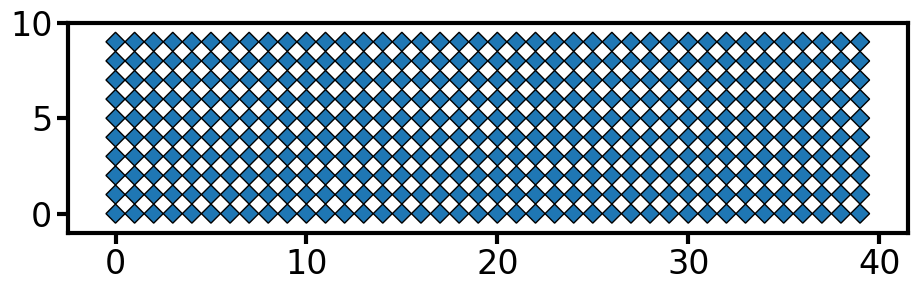

In [18]:
Ar.plot()

In [16]:
newdata

[[<AuxeticLib2Dv2.Poli at 0x71b858050ec0>,

In [100]:
import numpy as np
from jax import grad, jit
from jax import lax
from jax import random
import jax
import jax.numpy as jnp
import optax
from jaxopt import LBFGS, BFGS

jax.config.update("jax_enable_x64", True)

#Ar=Auxetic('random64Dual0.dat')
Ar=Auxetic('square10x10.dat')


boundaryPointer=[]
for poli in Ar:
    for pata in poli.patas:
        neigh=pata.myVecino
        pataN=pata.pataVecina
        if np.abs(poli.x-neigh.x)>0.5*Ar.Lx and poli.id>neigh.id: #poli.id>neigh.id pataN.valid==1 and pata.valid==1
            cutLinkV(poli,neigh)

for poli in Ar:
    for pata in poli.patas:
        neigh=pata.myVecino
        pataN=pata.pataVecina
        if np.abs(poli.y-neigh.y)>0.5*Ar.Ly and poli.id>neigh.id: #pataN.valid==1 and pata.valid==1
            boundaryPointer.append(poli)
            boundaryPointer.append(neigh)
            cutLinkV(poli,neigh)

removeLoneNodesV(Ar)
for point in boundaryPointer:
    if point not in Ar:
        boundaryPointer.remove(point) #remove "removed" nodes
boundaryPointer = list(dict.fromkeys(boundaryPointer)) #remove duplicates
boundary=[]
for ele in boundaryPointer:
    boundary.append(ele.id)




strain_steps=100
tot_strain=0.2
while_loop=0
tol=1e-8
Noise_Amplitude=1e-3
#indx_border1=slice(0,10*3)
#indx_border2=slice(-10*3,None)

##BERTOLDI/BOLEI values
# kl=47
# ks=16
# kt=0.0088
# kc=0.024
# gamma=-0.00088
# t0=0.1

kl=47
ks=47
kt=0.000088
kc=10000
gamma=-0.0000088
t0=0.0

Base_Foot_shape=np.array([0.5,0.8,0.7,0.8,0.9,1.1,1.1,1.2,1.2,0.8])/5.0


Lx=Ar.Lx
Ly=Ar.Ly
N=len(Ar)
deps=1.0/strain_steps*Ly*tot_strain

#create square grid
C=[] #Compatibility matrix
linkFlag=[] #tells you which kind of link you have... usefull for periodicity
Alphas=[] #rotation angle of vertex vector
q=[]
A=[]
eps=[]
Foot_shape=[]

q=Ar.getVar()
Avecs=[]

Nb=0
for poli in Ar:
    for pata in poli.patas:
        if pata.valid==1:
            neigh=pata.myVecino
            pataN=pata.pataVecina
            if neigh.id>poli.id:
                if (poli.id not in boundary or neigh.id not in boundary):
                    C.append([poli.id,neigh.id])
                    Avecs.append([pata.avec0,pataN.avec0])
                    pata.id=[Nb,0]
                    pataN.id=[Nb,1]
                    Nb+=1

c=Nb
for poli in Ar:
    for pata in poli.patas:
        if pata.id==[]: #I could diff between valid and not valid bonds, but I think it doesnt affect the result, unless vs modifies the borders
            neigh=pata.myVecino
            pataN=pata.pataVecina
            Avecs.append([pata.avec0,pataN.avec0])
            pata.id=[c,0]
            pataN.id=[c,1]
            C.append([poli.id,neigh.id])
            c+=1
            
                

neighIds=[]

for ij in C[:Nb]:
    i,j=ij
    poli1=Ar[i]
    poli2=Ar[j]
    for i,pata in enumerate(poli1.patas):
        if pata.myVecino==poli2:
            pata1=pata
            pata1i=i
            break
    for i,pata in enumerate(poli2.patas):
        if pata.myVecino==poli1:
            pata2=pata
            pata2i=i
            break
    n1=len(poli1.patas)
    n2=len(poli2.patas)
    neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])


for poli in Ar:
    eps.append(0.0) #x
    if poli.id in boundary:
        eps.append(-poli.y*deps/Ar.Ly) #y
    else:
        eps.append(0.0)
    eps.append(0.0) #t

strain_signs=[]
for i in range(strain_steps):
    strain_signs.append(1.0)
strain_signs=jnp.array(strain_signs)

neighIds=jnp.array(neighIds)
Avecs=jnp.array(Avecs)
C=jnp.array(C)
q=jnp.array(q)
eps=jnp.array(eps)
Foot_shape=jnp.array(Foot_shape)

boundary=jnp.array(boundary)
mask_border=jnp.full(len(q),True)
mask_border=mask_border.at[boundary*3+0].set(False)
mask_border=mask_border.at[boundary*3+1].set(False)
mask_border=mask_border.at[boundary*3+2].set(False)
inv_mask_border=~mask_border

def makeModel():

    def model(vs,ikey):

        def angleVecs(v,u): #gives the angle between v and u, measured counterclockwise from v to u
            return (jnp.arctan2(v[1],v[0]) - jnp.arctan2(u[1],u[0]))%(2*jnp.pi)

        indexmap1=jax.vmap(lambda x,y: x[y[0],y[1]],(None,0))
        indexmap=jax.vmap(indexmap1,(None,1),1) # Uses indexes from y, and elements from x, to create array.

        MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
        keys= jax.random.split(ikey,len(strain_signs))

        def Rotation(theta):
            return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
        RotationM=jax.vmap(Rotation)

        def interaction_potential(q,ij,rAvecs,rAvecsNN): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
            i,j=C.at[ij].get()
            avec1,avec2=rAvecs
            u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
            x1=q[3*i+0]
            y1=q[3*i+1]
            t1=q[3*i+2]
            x2=q[3*j+0]
            y2=q[3*j+1]
            t2=q[3*j+2]
            dl=jnp.array([x1-x2,y1-y2])
            dX=dl+avec1-avec2
            dx=dX.at[0].get()
            dy=dX.at[1].get()
            dl=dl/jnp.linalg.norm(dl)
            dlx=dl.at[0].get()
            dly=dl.at[1].get()
            dtheta=t1-t2
            cAngle1=angleVecs(d2-avec2,u1-avec1)-t0
            cAngle2=angleVecs(d1-avec1,u2-avec2)-t0

            stretching=(dlx*dx+dly*dy)**2*kl
            shearing=(-dly*dx+dlx*dy)**2*ks
            bending=dtheta**2*kt+dtheta**4*gamma
            contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*kc

            return stretching+shearing+bending
        def potential(q_NoBorders,border,vs):
            #border,=args
            q=jnp.zeros(len(q_NoBorders)+len(border))
            q=q.at[inv_mask_border].set(border)
            q=q.at[mask_border].set(q_NoBorders) # either this or I insert an array into another
            
            vsx=vs.at[0::2].get()
            vsy=vs.at[1::2].get()
            nvs=jnp.stack((vsx,vsy),axis=1)
            rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            Rb=R[C] #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors
            rAvecsNN=indexmap(rAvecs,neighIds)

            #podria armar una matriz/vector con todo los cosenos/senos aca, para aumentar eficiencia ~1/z
            return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs.at[ij].get(),rAvecsNN.at[ij].get()) ,0.0)/2.0 #
        def potential2(q,vs):
            vsx=vs.at[0::2].get()
            vsy=vs.at[1::2].get()
            nvs=jnp.stack((vsx,vsy),axis=1)
            rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
            R=RotationM(q.at[2::3].get()) #get rotation matrix
            Rb=R[C] #rotations in the space of bonds
            rAvecs=MpV(Rb,rAvecs) #get avec vectors

            return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs.at[ij].get()),0.0)/2.0
        #dV=grad(potential)
        dV_border=grad(potential2)

        optimizer=LBFGS(potential)#LBFGS(potential)#LBFGS(potential,tol=1e-10,maxiter=50000,min_stepsize=1e-10,maxls=100)
       
        def strain_fun(q,args):
            #ys=ys.at[0].set(eps)
            strain_sign,key=args
            qrand=(jax.random.uniform(key,shape=(N*3,))-0.5)*Noise_Amplitude
            qrand=qrand.at[inv_mask_border].set(0.0)

            q=q+eps*strain_sign+qrand
            
            
            border=q.at[inv_mask_border].get()
            q_NoBorder=q.at[mask_border].get()

            q_NoBorder,_=optimizer.run(q_NoBorder,border=border,vs=vs)#opt_loop(q_old)
            
            q=q.at[mask_border].set(q_NoBorder)

            return q,q
        
        def calcPressure(x,q):
            return x,jnp.sum(jnp.abs(dV_border(q,vs).at[boundary*3+1].get()))/2.0#sum(dV_border(q,vs).at[1:30:3].get())

        _,qs=lax.scan(strain_fun,q,(strain_signs,keys))#lax.scan(strain_fun,q,None,length=strain_steps)
        #_,pressure=lax.scan(calcPressure,None,qs)

        return qs#pressure,qs
    
    return model




In [106]:
def interaction_potential(q,ij,rAvecs): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
    i,j=C[ij]
    avec1,avec2=rAvecs[ij]
    x1=q[3*i+0]
    y1=q[3*i+1]
    t1=q[3*i+2]
    x2=q[3*j+0]
    y2=q[3*j+1]
    t2=q[3*j+2]
    dl=jnp.array([x1-x2,y1-y2])
    dX=dl+avec1-avec2
    dx=dX.at[0].get()
    dy=dX.at[1].get()
    dl=dl/jnp.linalg.norm(dl)
    dlx=dl.at[0].get()
    dly=dl.at[1].get()
    dtheta=t1-t2

    #stretching=(dlx*dx+dly*dy)**2
    #shearing=(-dly*dx+dlx*dy)**2
    #bending=dtheta**2*kt+dtheta**4*gamma
    print(sum(dX*dX))

    return sum(dX*dX)#stretching+shearing#+bending

def potential(q_NoBorders,border,vs):
    #border,=args
    q=jnp.zeros(len(q_NoBorders)+len(border))
    q=q.at[inv_mask_border].set(border)
    q=q.at[mask_border].set(q_NoBorders) # either this or I insert an array into another
    
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)
    rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
    R=RotationM(q.at[2::3].get()) #get rotation matrix
    Rb=R[C] #rotations in the space of bonds
    rAvecs=MpV(Rb,rAvecs) #get avec vectors

    #podria armar una matriz/vector con todo los cosenos/senos aca, para aumentar eficiencia ~1/z
    return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs[ij]) ,0.0)/2.0 #
def potential2(q,vs):
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)
    rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
    R=RotationM(q.at[2::3].get()) #get rotation matrix
    Rb=R[C] #rotations in the space of bonds
    rAvecs=MpV(Rb,rAvecs) #get avec vectors

    return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs[ij]) ,0.0)/2.0

In [188]:
def angleVecs(u,v): #gives the angle between v and u, measured counterclockwise from v to u
    return (jnp.arctan2(v[1],v[0]) - jnp.arctan2(u[1],u[0]))%(2*jnp.pi)

indexmap1=jax.vmap(lambda x,y: x[y[0],y[1]],(None,0))
indexmap=jax.vmap(indexmap1,(None,1),1) # Uses indexes from y, and elements from x, to create array.

MpV = jax.vmap(jax.vmap(lambda x,y: x@y, (0,0), 0), (1,1), 1) #Operates Array of matrices N x [2 x [2 x 2]] with array of vectors N x [2 x [2]]
keys= jax.random.split(key,len(strain_signs))

def Rotation(theta):
    return jnp.array([[jnp.cos(theta),-jnp.sin(theta)],[jnp.sin(theta),jnp.cos(theta)]])
RotationM=jax.vmap(Rotation)

def interaction_potential(q,ij,rAvecs,rAvecsNN): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
    i,j=C.at[ij].get()
    avec1,avec2=rAvecs
    u1,d2,u2,d1=rAvecsNN #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
    x1=q[3*i+0]
    y1=q[3*i+1]
    t1=q[3*i+2]
    x2=q[3*j+0]
    y2=q[3*j+1]
    t2=q[3*j+2]
    dl=jnp.array([x1-x2,y1-y2])
    dX=dl+avec1-avec2
    dx=dX.at[0].get()
    dy=dX.at[1].get()
    dl=dl/jnp.linalg.norm(dl)
    dlx=dl.at[0].get()
    dly=dl.at[1].get()
    dtheta=t1-t2
    cAngle1=angleVecs(d2-avec2,u1-avec1)-t0
    cAngle2=angleVecs(d1-avec1,u2-avec2)-t0

    stretching=(dlx*dx+dly*dy)**2*kl
    shearing=(-dly*dx+dlx*dy)**2*ks
    bending=dtheta**2*kt+dtheta**4*gamma
    contact=(jnp.heaviside(-cAngle1, 0.0)*cAngle1**2+jnp.heaviside(-cAngle2, 0.0)*cAngle2**2)*kc
    #print(cAngle1+cAngle2)
    print(i,j,rAvecsNN)
    return contact#shearing+bending++stretching
def potential(q_NoBorders,border,vs):
    #border,=args
    q=jnp.zeros(len(q_NoBorders)+len(border))
    q=q.at[inv_mask_border].set(border)
    q=q.at[mask_border].set(q_NoBorders) # either this or I insert an array into another
    
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)
    rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
    R=RotationM(q.at[2::3].get()) #get rotation matrix
    Rb=R[C] #rotations in the space of bonds
    rAvecs=MpV(Rb,rAvecs) #get avec vectors
    rAvecsNN=indexmap(rAvecs,neighIds)

    #podria armar una matriz/vector con todo los cosenos/senos aca, para aumentar eficiencia ~1/z
    return lax.fori_loop(0,Nb, lambda ij,V: V+interaction_potential(q,ij,rAvecs.at[ij].get(),rAvecsNN.at[ij].get()) ,0.0)/2.0 #

In [142]:
Ar=Auxetic('square10x10.dat')


boundaryPointer=[]
for poli in Ar:
    for pata in poli.patas:
        neigh=pata.myVecino
        pataN=pata.pataVecina
        if np.abs(poli.x-neigh.x)>0.5*Ar.Lx and poli.id>neigh.id: #poli.id>neigh.id pataN.valid==1 and pata.valid==1
            cutLinkV(poli,neigh)

for poli in Ar:
    for pata in poli.patas:
        neigh=pata.myVecino
        pataN=pata.pataVecina
        if np.abs(poli.y-neigh.y)>0.5*Ar.Ly and poli.id>neigh.id: #pataN.valid==1 and pata.valid==1
            boundaryPointer.append(poli)
            boundaryPointer.append(neigh)
            cutLinkV(poli,neigh)

removeLoneNodesV(Ar)
for point in boundaryPointer:
    if point not in Ar:
        boundaryPointer.remove(point) #remove "removed" nodes
boundaryPointer = list(dict.fromkeys(boundaryPointer)) #remove duplicates
boundary=[]
for ele in boundaryPointer:
    boundary.append(ele.id)




strain_steps=100
tot_strain=0.2
while_loop=0
tol=1e-8
Noise_Amplitude=1e-3
#indx_border1=slice(0,10*3)
#indx_border2=slice(-10*3,None)

##BERTOLDI/BOLEI values
# kl=47
# ks=16
# kt=0.0088
# kc=0.024
# gamma=-0.00088
# t0=0.1

kl=47
ks=47
kt=0.000088
kc=10000
gamma=-0.0000088
t0=0.0

Base_Foot_shape=np.array([0.5,0.8,0.7,0.8,0.9,1.1,1.1,1.2,1.2,0.8])/5.0


Lx=Ar.Lx
Ly=Ar.Ly
N=len(Ar)
deps=1.0/strain_steps*Ly*tot_strain

#create square grid
C=[] #Compatibility matrix
linkFlag=[] #tells you which kind of link you have... usefull for periodicity
Alphas=[] #rotation angle of vertex vector
q=[]
A=[]
eps=[]
Foot_shape=[]

q=Ar.getVar()
Avecs=[]

Nb=0
for poli in Ar:
    for pata in poli.patas:
        if pata.valid==1:
            neigh=pata.myVecino
            pataN=pata.pataVecina
            if neigh.id>poli.id:
                if (poli.id not in boundary or neigh.id not in boundary):
                    C.append([poli.id,neigh.id])
                    Avecs.append([pata.avec0,pataN.avec0])
                    pata.id=[Nb,0]
                    pataN.id=[Nb,1]
                    Nb+=1

c=Nb
for poli in Ar:
    for pata in poli.patas:
        if pata.id==[]: #I could diff between valid and not valid bonds, but I think it doesnt affect the result, unless vs modifies the borders
            neigh=pata.myVecino
            pataN=pata.pataVecina
            Avecs.append([pata.avec0,pataN.avec0])
            pata.id=[c,0]
            pataN.id=[c,1]
            C.append([poli.id,neigh.id])
            c+=1
            
                

neighIds=[]

for ij in C[:Nb]:
    i,j=ij
    poli1=Ar[i]
    poli2=Ar[j]
    for i,pata in enumerate(poli1.patas):
        if pata.myVecino==poli2:
            pata1=pata
            pata1i=i
            break
    for i,pata in enumerate(poli2.patas):
        if pata.myVecino==poli1:
            pata2=pata
            pata2i=i
            break
    n1=len(poli1.patas)
    n2=len(poli2.patas)
    neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])


for poli in Ar:
    eps.append(0.0) #x
    if poli.id in boundary:
        eps.append(-poli.y*deps/Ar.Ly) #y
    else:
        eps.append(0.0)
    eps.append(0.0) #t

strain_signs=[]
for i in range(strain_steps):
    strain_signs.append(1.0)
strain_signs=jnp.array(strain_signs)

neighIds=jnp.array(neighIds)
Avecs=jnp.array(Avecs)
C=jnp.array(C)
q=jnp.array(q)
eps=jnp.array(eps)
Foot_shape=jnp.array(Foot_shape)

boundary=jnp.array(boundary)
mask_border=jnp.full(len(q),True)
mask_border=mask_border.at[boundary*3+0].set(False)
mask_border=mask_border.at[boundary*3+1].set(False)
mask_border=mask_border.at[boundary*3+2].set(False)
inv_mask_border=~mask_border

In [189]:
q=result[0]
vsx=vs.at[0::2].get()
vsy=vs.at[1::2].get()
nvs=jnp.stack((vsx,vsy),axis=1)
rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
R=RotationM(q.at[2::3].get()) #get rotation matrix
Rb=R[C] #rotations in the space of bonds
rAvecs=MpV(Rb,rAvecs) #get avec vectors
rAvecsNN=indexmap(rAvecs,neighIds)
V=0.0
for ij in range(Nb):
    t=interaction_potential(q,ij,rAvecs[ij],rAvecsNN[ij])
    V+=t
    #print(t)
    
print(V/2.0)

0 10 [[-5.00000000e-01 -6.12323400e-17]
 [-5.00000000e-01 -7.09577978e-06]
 [ 5.00000000e-01  7.09577978e-06]
 [ 5.00000000e-01  0.00000000e+00]]
1 11 [[-5.00000000e-01 -6.12323400e-17]
 [-5.00000000e-01  2.19378177e-06]
 [ 5.00000000e-01 -2.19378177e-06]
 [ 5.00000000e-01  0.00000000e+00]]
2 12 [[-5.000000e-01 -6.123234e-17]
 [-5.000000e-01 -2.395676e-06]
 [ 5.000000e-01  2.395676e-06]
 [ 5.000000e-01  0.000000e+00]]
3 13 [[-5.00000000e-01 -6.12323400e-17]
 [-5.00000000e-01 -1.94420317e-06]
 [ 5.00000000e-01  1.94420317e-06]
 [ 5.00000000e-01  0.00000000e+00]]
4 14 [[-5.00000000e-01 -6.12323400e-17]
 [-5.00000000e-01  1.28210186e-06]
 [ 5.00000000e-01 -1.28210186e-06]
 [ 5.00000000e-01  0.00000000e+00]]
5 15 [[-5.00000000e-01 -6.12323400e-17]
 [-5.00000000e-01 -5.69268636e-06]
 [ 5.00000000e-01  5.69268636e-06]
 [ 5.00000000e-01  0.00000000e+00]]
6 16 [[-5.00000000e-01 -6.12323400e-17]
 [-5.00000000e-01  1.04400635e-05]
 [ 5.00000000e-01 -1.04400635e-05]
 [ 5.00000000e-01  0.00000000e

In [174]:
for kk,q in enumerate(result):
    vsx=vs.at[0::2].get()
    vsy=vs.at[1::2].get()
    nvs=jnp.stack((vsx,vsy),axis=1)
    rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
    R=RotationM(q.at[2::3].get()) #get rotation matrix
    Rb=R[C] #rotations in the space of bonds
    rAvecs=MpV(Rb,rAvecs) #get avec vectors
    rAvecsNN=indexmap(rAvecs,neighIds)
    V=0.0
    for ij in range(Nb):
        t=interaction_potential(q,ij,rAvecs[ij],rAvecsNN[ij])
        V+=t
        #print(t)
        
    print(kk,V/2.0)

0 0.0
1 0.0
2 0.0
3 0.0
4 0.0
5 0.0
6 0.0
7 0.0
8 0.0
9 0.0
10 0.0
11 0.0
12 0.0
13 0.0
14 0.0
15 0.0
16 0.0
17 0.0
18 0.0
19 0.0
20 0.0
21 0.0
22 0.0
23 0.0
24 0.0
25 0.0
26 0.0
27 0.0
28 0.0
29 0.0
30 0.0
31 0.0
32 0.0
33 0.0
34 0.0
35 0.0
36 0.0
37 0.0
38 0.0
39 0.0
40 0.0
41 0.0
42 0.0
43 0.0
44 0.0
45 0.0
46 0.0
47 0.0
48 0.0
49 0.0
50 0.0
51 0.0
52 0.0
53 0.0
54 0.0
55 0.0
56 0.0
57 0.0
58 0.0
59 0.0
60 0.0
61 0.0
62 0.0
63 0.0
64 0.0
65 0.0
66 0.0
67 0.0
68 0.0
69 0.0
70 0.0
71 0.0
72 0.0
73 0.0
74 0.0
75 0.0
76 0.0
77 0.0
78 0.0
79 0.0
80 0.0
81 0.0
82 0.0
83 0.0
84 0.0
85 0.0
86 0.0
87 0.0
88 0.0
89 0.0
90 0.0
91 0.0
92 0.0
93 0.0
94 0.0
95 0.0
96 0.0
97 0.0
98 0.0
99 0.0


In [146]:
q=jnp.array(Ar.getVar())#result[0]#


0.0


In [159]:
4.712394326615252%(2*np.pi)

4.712394326615252

In [123]:
def interaction_potential(q,ij,rAvecs): #puedes tener precalculado el cos, sin de theta, estilo st, y ct. Y precalcular el sin/cos de alpha, estilo CAlphas y SAlphas
    i,j=C[ij]
    avec1,avec2=rAvecs[ij]
    x1=q[3*i+0]
    y1=q[3*i+1]
    t1=q[3*i+2]
    x2=q[3*j+0]
    y2=q[3*j+1]
    t2=q[3*j+2]
    dl=jnp.array([x1-x2,y1-y2])
    dX=dl+avec1-avec2
    dx=dX.at[0].get()
    dy=dX.at[1].get()
    dl=dl/jnp.linalg.norm(dl)
    dlx=dl.at[0].get()
    dly=dl.at[1].get()
    dtheta=t1-t2
    print(sum(dX*dX)) 
    return sum(dX*dX)

In [126]:
for i in
interaction_potential(q,1,rAvecs)

3.009265538105056e-36


Array(3.00926554e-36, dtype=float64)

In [116]:
ij=0
i,j=C[ij]
avec1,avec2=rAvecs[ij]
x1=q[3*i+0]
y1=q[3*i+1]
t1=q[3*i+2]
x2=q[3*j+0]
y2=q[3*j+1]
t2=q[3*j+2]
dl=jnp.array([x1-x2,y1-y2])
dX=dl+avec1-avec2
dx=dX.at[0].get()
dy=dX.at[1].get()
dl=dl/jnp.linalg.norm(dl)
dlx=dl.at[0].get()
dly=dl.at[1].get()
dtheta=t1-t2

In [112]:
C[0]

Array([  0, 141], dtype=int64)

In [117]:
dX

Array([0.00000000e+00, 2.05998413e-18], dtype=float64)

In [61]:
jnp.array([x1-x2,y1-y2])

Array([ 0.60208015, -0.09218612], dtype=float64)

In [94]:
dl=jnp.array([x1-x2,y1-y2])

In [93]:
x1-x2

Array(0.0560459, dtype=float64)

In [92]:
Ar[141].x

0.6040488500286085

In [95]:
dl

Array([0.0560459 , 0.00071744], dtype=float64)

In [82]:
Ar[0].x-Ar[141].x

0.05604589511797342

-0.11689922243784423


(-1.0, 10.0, -0.9540999999999983, 9.036099999999964)

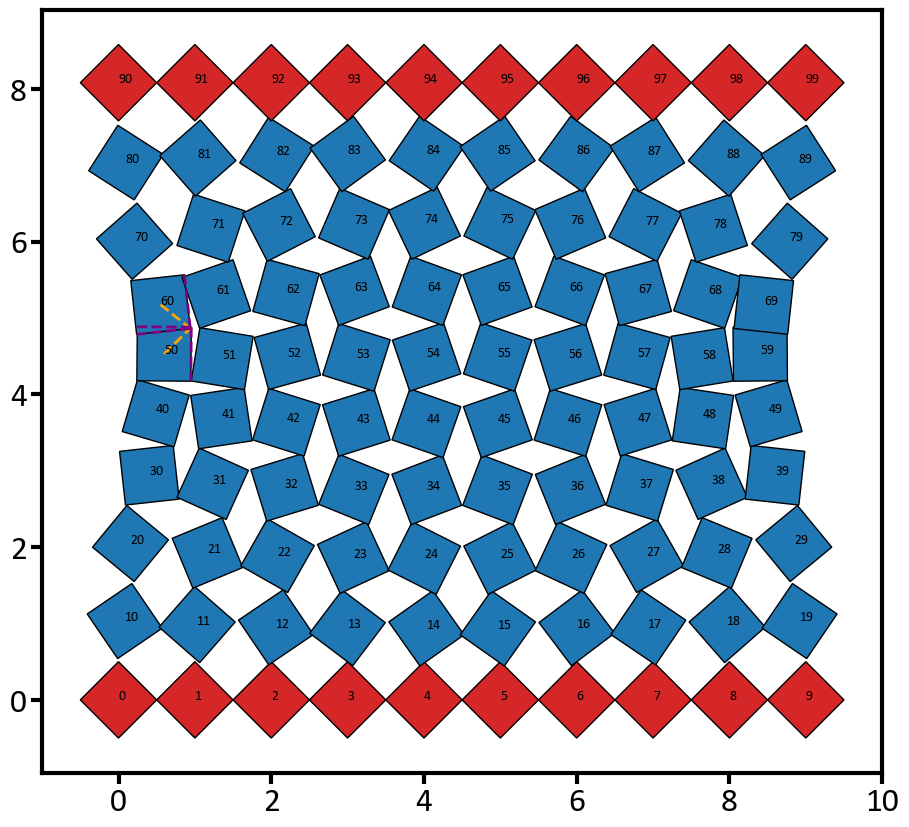

In [281]:
q=result[50]
vsx=vs.at[0::2].get()
vsy=vs.at[1::2].get()
nvs=jnp.stack((vsx,vsy),axis=1)
rAvecs=Avecs.at[:Nb].add(nvs[:,jnp.newaxis,:])
R=RotationM(q.at[2::3].get()) #get rotation matrix
Rb=R[C] #rotations in the space of bonds
rAvecs=MpV(Rb,rAvecs) #get avec vectors
rAvecsNN=indexmap(rAvecs,neighIds)


self=Ar
self.setVar(q)
plt.figure()
for poli in self:
    avecs=[np.array(pata.avec)+np.array([poli.x,poli.y]) for pata in poli.patas]
    color='C0'
    if poli.id in boundary:
        color='C3'
    if len(avecs)<3:
        avecs.append([poli.x,poli.y])
    avecs=np.array(avecs)
    plt.gca().add_patch(matplotlib.patches.Polygon(avecs,edgecolor='black',facecolor=color))
    plt.text(poli.x,poli.y,str(poli.id),size=10)

for k,ij in enumerate(C[:Nb]):
    i,j=ij
    if (i==60 and j==50) or (j==60 and i==50):
        avec1,avec2=rAvecs.at[k].get()
        u1,d2,u2,d1=rAvecsNN[k] #neighIds.append([(poli1.patas[(pata1i+1)%n1]).id,(poli2.patas[(pata2i-1)%n2]).id,(poli2.patas[(pata2i+1)%n2]).id,(poli1.patas[(pata1i-1)%n1]).id])
        x1=q[3*i+0]
        y1=q[3*i+1]
        x2=q[3*j+0]
        y2=q[3*j+1]
        v2u=u2-avec2
        v1u=u1-avec1
        v1d=d1-avec1
        v2d=d2-avec2
        X1=np.array([x1,y1])
        X2=np.array([x2,y2])
        
        #cAngle1=angleVecs(d2-avec2,u1-avec1)-t0
        #cAngle2=angleVecs(d1-avec1,u2-avec2)-t0
        print(angleVecs(v2d,v1u))
        plt.plot([x1,x1+avec1[0]],[y1,y1+avec1[1]],'--',color='orange',lw=2)
        plt.plot([x2,x2+avec2[0]],[y2,y2+avec2[1]],'--',color='orange',lw=2)
        base=X2+avec2
        plt.plot([base[0],base[0]+v2u[0]],[base[1],base[1]+v2u[1]],'--',color='purple',lw=2)
        plt.plot([base[0],base[0]+v2d[0]],[base[1],base[1]+v2d[1]],'--',color='purple',lw=2)

        base=X1+avec1
        plt.plot([base[0],base[0]+v1u[0]],[base[1],base[1]+v1u[1]],'--',color='purple',lw=2)
        plt.plot([base[0],base[0]+v1d[0]],[base[1],base[1]+v1d[1]],'--',color='purple',lw=2)

        #plt.plot([x1+avec1[0],x1+u1[0]],[y1+avec1[1],y1+u1[1]],'--',color='purple',lw=2)
        #plt.plot([x2+avec2[0],x2+d2[0]],[y2+avec2[1],y2+d2[1]],'--',color='purple',lw=2)
        #plt.plot([x1,x1+d1[0]],[y1,y1+d1[1]],'--',color='red',lw=2)
plt.axis('scaled')
#plt.xlim(0,Ar.Lx)
#plt.axis('off')

In [265]:
def angleVecs(u,v): 
    return (jnp.arctan2(u[1],u[0])-jnp.arctan2(v[1],v[0]))%(2*jnp.pi)

In [271]:
x=0
y=-1
jnp.arctan2(y,x)

Array(-1.57079633, dtype=float64, weak_type=True)

In [210]:
avec1,avecs2=rAvecs.at[0].get()

In [211]:
avec1

Array([3.061617e-17, 5.000000e-01], dtype=float64)

In [212]:
avec2

Array([[ 5.00000000e-01,  7.09577978e-06],
       [-5.00000000e-01,  2.19378177e-06]], dtype=float64)

In [209]:
rAvecs[0][1]

Array([ 7.09577978e-06, -5.00000000e-01], dtype=float64)

In [222]:
for i in rAvecs:
    if len(i)!=2:
        print(len(i))

In [15]:
import jaxopt

In [27]:
def g(vs):
    return vs**2



def f(vs):
    beta=g(vs)
    def h(x,beta):
        return x**2*beta**2

    opt=BFGS(h)
    sol,_=opt.run(1.0,beta=beta)
    return sol  

In [31]:
def g(vs):
    return vs**2



def f(vs):
    beta=g(vs)
    def h(x):
        return x**2*beta**2

    opt=BFGS(h)
    sol,_=opt.run(1.0)
    return sol  

In [32]:
jf=jax.jit(f)

In [33]:
mg=jax.grad(jf)

In [34]:
mg(2.0)

CustomVJPException: Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how to differentiate the custom_vjp function with respect to explicit input parameters. Try passing the closed-over value into the custom_vjp function as an argument, and adapting the custom_vjp fwd and bwd rules.

In [64]:
vs[-4:]/vs[-4:][1]

Array([ 3.40425532e-01,  1.00000000e+00,  1.87234043e-04, -1.87234043e-05],      dtype=float64)

In [60]:
1.6/4.7

0.3404255319148936

In [65]:
x[-4:]/x[-4:][1]

array([0.41348814, 1.        , 0.02764895, 0.00505973])

In [66]:
x3[-4:]/x3[-4:][1]

array([ 4.60508005e-01,  1.00000000e+00,  5.95806245e-02, -1.92320253e-05])

In [70]:
opt.last_optimize_result()

6

In [71]:
myloss(x)

Array(13.61866042, dtype=float64)